In [3]:

# =========================================
# ARTI 502 - Assignment 2
# Task 1: Getting the CIFAR-10 Dataset
# =========================================

import torch
import torchvision
from torchvision import datasets, transforms
from pathlib import Path

# 1. Check PyTorch and GPU
print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Set dataset directory
DATA_PATH = Path("/content/cifar_data")
DATA_PATH.mkdir(parents=True, exist_ok=True)

# 3. Convert images to tensors
transform = transforms.ToTensor()

# 4. Load training dataset
train_dataset = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=True,
    transform=transform
)

# 5. Load testing dataset
test_dataset = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=True,
    transform=transform
)

# 6. Display dataset information
print("\nCIFAR-10 Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Number of Classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)

# 7. Verify image dimensions
image, label = train_dataset[0]

print("\nSingle Image Shape:", image.shape)
print("Sample Label:", train_dataset.classes[label])


PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
Device: cuda
GPU: NVIDIA L4


100%|██████████| 170M/170M [33:43<00:00, 84.3kB/s]



CIFAR-10 Dataset Loaded Successfully!
Training Images: 50000
Testing Images: 10000
Number of Classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Single Image Shape: torch.Size([3, 32, 32])
Sample Label: frog


In [4]:

# ==========================================
# Task 2: Define a Convolutional Neural Network
# ==========================================

import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolution block
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Second convolution block
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Third convolution block
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Fully connected classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.classifier(x)
        return x


# Create the model
model = CNN().to(device)

# Print its architecture
print(model)

# Test the forward pass with a dummy image
dummy_image = torch.randn(
    1, 3, 32, 32, device=device
)

model.eval()

with torch.no_grad():
    output = model(dummy_image)

print("\nDevice:", device)
print("Input Shape:", dummy_image.shape)
print("Output Shape:", output.shape)
print("CNN Model Created Successfully!")


CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256,

In [5]:

# =====================================
# Task 2: Training Function
# =====================================

def train_one_epoch(model, train_loader, criterion, optimizer, device):

    # 1. Enable training mode
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    # 2. Process training batches
    for images, labels in train_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Forward pass
        outputs = model(images)

        # 5. Calculate loss
        loss = criterion(outputs, labels)

        # 6. Backpropagation
        loss.backward()

        # 7. Update model weights
        optimizer.step()

        # 8. Calculate training statistics
        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += batch_size

    # 9. Calculate epoch averages
    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


print("Training function created successfully!")


Training function created successfully!


In [6]:

# =====================================
# Task 2: Testing / Evaluation Function
# =====================================

def evaluate(model, data_loader, criterion, device):

    # 1. Enable evaluation mode
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    # 2. Disable gradient calculations
    with torch.no_grad():

        for images, labels in data_loader:

            # Move data to GPU
            images = images.to(device)
            labels = labels.to(device)

            # 3. Forward pass
            outputs = model(images)

            # 4. Calculate loss
            loss = criterion(outputs, labels)

            # 5. Calculate statistics
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += batch_size

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


print("Evaluation function created successfully!")


Evaluation function created successfully!


In [7]:

from torch.utils.data import TensorDataset, DataLoader

# Create a separate temporary model
test_model = CNN().to(device)

# Synthetic images and labels for function testing
dummy_images = torch.randn(8, 3, 32, 32)
dummy_labels = torch.randint(0, 10, (8,))

dummy_loader = DataLoader(
    TensorDataset(dummy_images, dummy_labels),
    batch_size=4
)

criterion = nn.CrossEntropyLoss()

test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=0.001
)

# Check both functions
train_loss, train_acc = train_one_epoch(
    test_model, dummy_loader,
    criterion, test_optimizer, device
)

eval_loss, eval_acc = evaluate(
    test_model, dummy_loader,
    criterion, device
)

print("Training Function: PASSED")
print("Evaluation Function: PASSED")
print("Test Loss:", round(eval_loss, 4))
print("Test Accuracy:", round(eval_acc, 2), "%")


Training Function: PASSED
Evaluation Function: PASSED
Test Loss: 2.0924
Test Accuracy: 37.5 %


In [8]:

# ======================================
# Task 3: Loading and Inspecting CIFAR-10
# ======================================

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATA_PATH = Path("/content/cifar_data")

try:
    train_dataset = datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=transforms.ToTensor()
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    images, labels = next(iter(train_loader))

    print("Dataset READY!")
    print("Images Tensor Shape:", images.shape)
    print("Labels Tensor Shape:", labels.shape)
    print("Images Data Type:", images.dtype)
    print("Pixel Min:", images.min().item())
    print("Pixel Max:", images.max().item())

except RuntimeError:
    print("Dataset is missing from the new runtime.")
    print("Restore the previous backup before continuing.")


Dataset READY!
Images Tensor Shape: torch.Size([128, 3, 32, 32])
Labels Tensor Shape: torch.Size([128])
Images Data Type: torch.float32
Pixel Min: 0.0
Pixel Max: 1.0


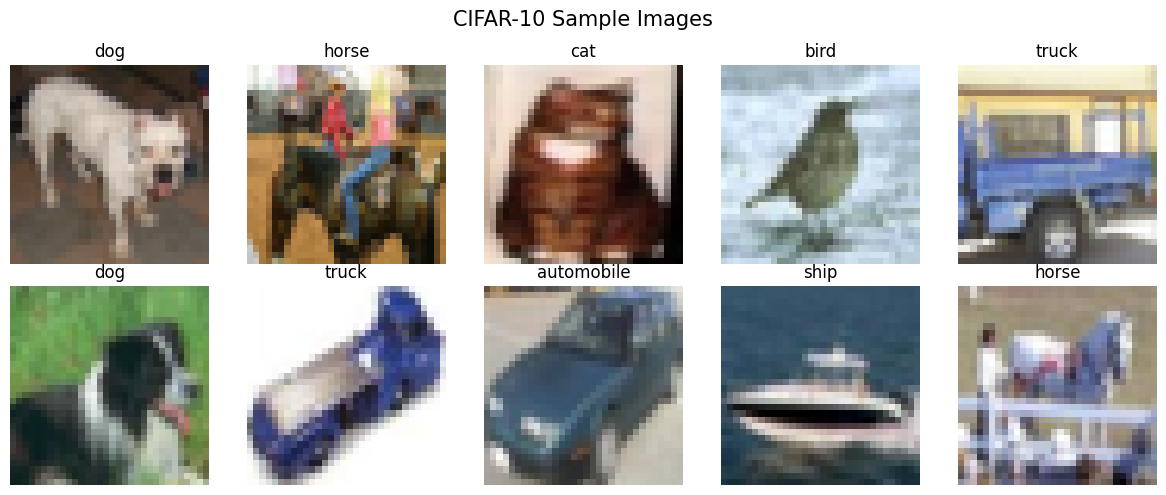

Visualization created successfully!


In [9]:

# ==========================================
# Task 3: CIFAR-10 Image Visualization
# ==========================================

import matplotlib.pyplot as plt

# CIFAR-10 class names
classes = train_dataset.classes

# Create a figure with 10 images
fig, axes = plt.subplots(
    2, 5, figsize=(12, 5)
)

# Show the first 10 images from the batch
for i, ax in enumerate(axes.flat):

    image = images[i]
    label = labels[i].item()

    # Convert PyTorch format [C, H, W]
    # to Matplotlib format [H, W, C]
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle(
    "CIFAR-10 Sample Images",
    fontsize=15
)

plt.tight_layout()

# Save figure for the report
plt.savefig(
    "/content/Task3_CIFAR10_Visualization.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Visualization created successfully!")


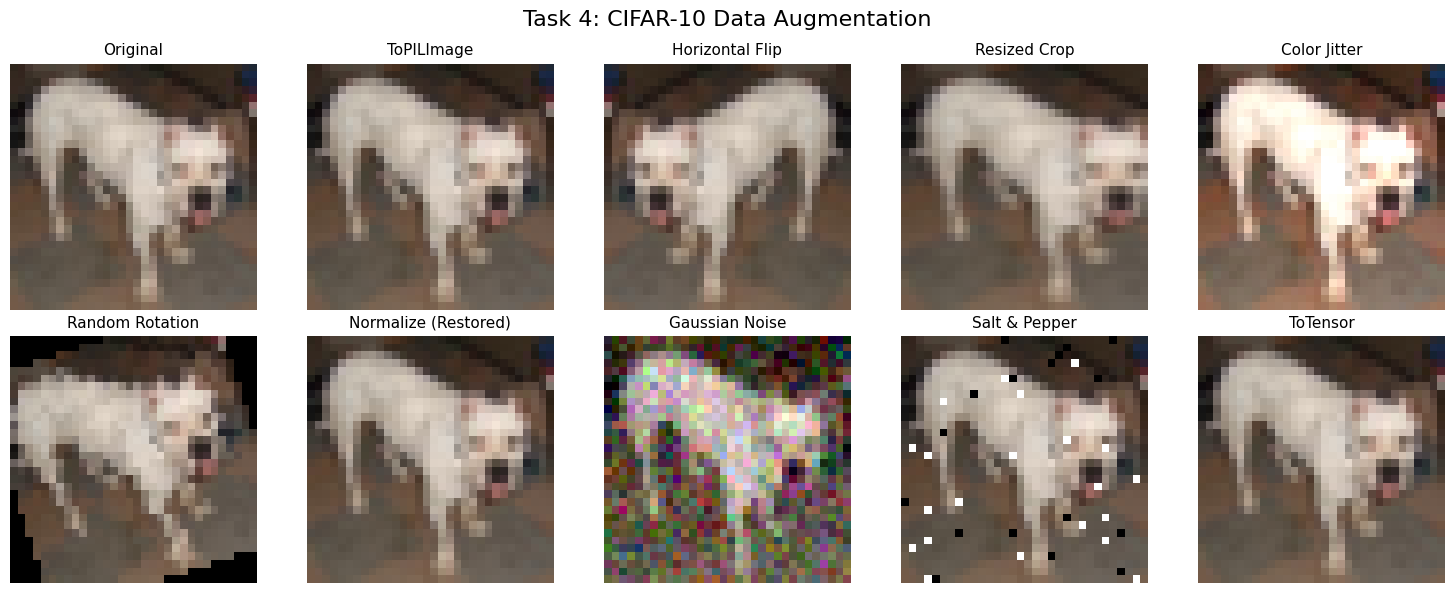

All augmentation demonstrations completed!


In [10]:

# ==========================================
# Task 4: Dataset Augmentation Demonstration
# ==========================================

import torch
import matplotlib.pyplot as plt
from torchvision import transforms

torch.manual_seed(42)

# Use one real CIFAR-10 image from Task 3
original_tensor = images[0].cpu()

# CIFAR-10 normalization values
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

# 1. ToPILImage
pil_image = transforms.ToPILImage()(original_tensor)

# 2. RandomHorizontalFlip
flipped = transforms.RandomHorizontalFlip(
    p=1.0
)(pil_image)

# 3. RandomResizedCrop
cropped = transforms.RandomResizedCrop(
    size=32,
    scale=(0.7, 1.0)
)(pil_image)

# 4. ColorJitter
jittered = transforms.ColorJitter(
    brightness=0.4,
    contrast=0.4,
    saturation=0.4,
    hue=0.1
)(pil_image)

# 5. RandomRotation
rotated = transforms.RandomRotation(
    degrees=25
)(pil_image)

# 6. Normalize
normalized = transforms.Normalize(
    MEAN, STD
)(original_tensor.clone())

# Reverse normalization for visualization
mean_tensor = torch.tensor(MEAN).view(3, 1, 1)
std_tensor = torch.tensor(STD).view(3, 1, 1)

normalized_display = (
    normalized * std_tensor + mean_tensor
).clamp(0, 1)

# 7a. Gaussian Noise
gaussian_noise = (
    original_tensor +
    torch.randn_like(original_tensor) * 0.10
).clamp(0, 1)

# 7b. Salt-and-Pepper Noise
salt_pepper = original_tensor.clone()

random_map = torch.rand(
    1, original_tensor.shape[1],
    original_tensor.shape[2]
)

salt_pepper = torch.where(
    random_map < 0.025,
    torch.zeros_like(salt_pepper),
    salt_pepper
)

salt_pepper = torch.where(
    random_map > 0.975,
    torch.ones_like(salt_pepper),
    salt_pepper
)

# 8. ToTensor
tensor_converted = transforms.ToTensor()(pil_image)

# Display all augmentations
examples = [
    ("Original", original_tensor),
    ("ToPILImage", pil_image),
    ("Horizontal Flip", flipped),
    ("Resized Crop", cropped),
    ("Color Jitter", jittered),
    ("Random Rotation", rotated),
    ("Normalize (Restored)", normalized_display),
    ("Gaussian Noise", gaussian_noise),
    ("Salt & Pepper", salt_pepper),
    ("ToTensor", tensor_converted)
]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (title, img) in zip(axes.flat, examples):

    if isinstance(img, torch.Tensor):
        img = img.permute(1, 2, 0).numpy()

    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.suptitle(
    "Task 4: CIFAR-10 Data Augmentation",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/Task4_Augmentation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("All augmentation demonstrations completed!")


In [11]:

# ==========================================
# Task 4: Training and Evaluation Transforms
# ==========================================

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

SEED = 42
BATCH_SIZE = 128

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

# Augmentation for training only
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Two dataset instances with different transforms
full_train_aug = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=train_transform
)

full_train_eval = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=eval_transform
)

test_data = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=eval_transform
)

# Reproducible 45K / 5K split
generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    50000, generator=generator
).tolist()

train_indices = indices[:45000]
val_indices = indices[45000:]

train_data = Subset(
    full_train_aug, train_indices
)

val_data = Subset(
    full_train_eval, val_indices
)

# DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Verification
train_images, train_labels = next(iter(train_loader))

print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_data))
print("Batch Shape:", train_images.shape)
print("All DataLoaders Created Successfully!")


Training Samples: 45000
Validation Samples: 5000
Testing Samples: 10000
Batch Shape: torch.Size([128, 3, 32, 32])
All DataLoaders Created Successfully!


In [12]:

# ==========================================
# Task 5: Advanced CNN Training Setup
# ==========================================

# Install pretrained model library
!pip -q install timm

import torch
import timm
from pathlib import Path
from google.colab import drive

# Connect Google Drive to save checkpoints
drive.mount("/content/drive")

# Create a permanent folder for Assignment 2
SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Check GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
        "GB"
    )

# Check existing CIFAR-10 datasets
print("Training Samples:", len(train_data))
print("Validation Samples:", len(val_data))
print("Testing Samples:", len(test_data))

# Check available pretrained CNN models
models = timm.list_models(
    "*efficientnetv2*",
    pretrained=True
)

print("\nAvailable EfficientNetV2 Models:")
print(models[:15])

print("\nSave Directory:", SAVE_DIR)
print("ADVANCED TRAINING SETUP READY!")


Mounted at /content/drive
Device: cuda
GPU: NVIDIA L4
GPU Memory: 22.0 GB
Training Samples: 45000
Validation Samples: 5000
Testing Samples: 10000

Available EfficientNetV2 Models:
['efficientnetv2_rw_m.agc_in1k', 'efficientnetv2_rw_s.ra2_in1k', 'efficientnetv2_rw_t.ra2_in1k', 'gc_efficientnetv2_rw_t.agc_in1k', 'tf_efficientnetv2_b0.in1k', 'tf_efficientnetv2_b1.in1k', 'tf_efficientnetv2_b2.in1k', 'tf_efficientnetv2_b3.in1k', 'tf_efficientnetv2_b3.in21k', 'tf_efficientnetv2_b3.in21k_ft_in1k', 'tf_efficientnetv2_l.in1k', 'tf_efficientnetv2_l.in21k', 'tf_efficientnetv2_l.in21k_ft_in1k', 'tf_efficientnetv2_m.in1k', 'tf_efficientnetv2_m.in21k']

Save Directory: /content/drive/MyDrive/ARTI502_Assignment2
ADVANCED TRAINING SETUP READY!


In [13]:

# ==========================================
# Task 5: EfficientNetV2-L Preparation
# ==========================================

import torch
import timm

from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, Subset

MODEL_NAME = "tf_efficientnetv2_l.in21k_ft_in1k"
IMAGE_SIZE = 320
ADV_BATCH_SIZE = 4

# 1. Load ImageNet-pretrained CNN
advanced_model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=10
).to(device)

# 2. Read preprocessing settings
data_config = timm.data.resolve_model_data_config(
    advanced_model
)

mean = data_config["mean"]
std = data_config["std"]

print("Model:", MODEL_NAME)
print("Original Input Size:", data_config["input_size"])
print("Our Input Size:", IMAGE_SIZE)
print("Normalization Mean:", mean)
print("Normalization STD:", std)

# 3. Training transformations
advanced_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 4. Validation transformations
advanced_eval_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 5. Reuse exactly the same train/val indices
advanced_full_train = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=advanced_train_transform
)

advanced_full_val = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=advanced_eval_transform
)

advanced_train_data = Subset(
    advanced_full_train, train_indices
)

advanced_val_data = Subset(
    advanced_full_val, val_indices
)

# 6. Create new DataLoaders
advanced_train_loader = DataLoader(
    advanced_train_data,
    batch_size=ADV_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

advanced_val_loader = DataLoader(
    advanced_val_data,
    batch_size=ADV_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 7. Test one forward pass
sample_images, sample_labels = next(
    iter(advanced_train_loader)
)

sample_images = sample_images.to(device)

advanced_model.eval()

with torch.inference_mode():
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = advanced_model(sample_images)

assert outputs.shape == (
    ADV_BATCH_SIZE, 10
)

print("\nTraining:", len(advanced_train_data))
print("Validation:", len(advanced_val_data))
print("Input Shape:", sample_images.shape)
print("Output Shape:", outputs.shape)
print("EfficientNetV2-L READY!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  476MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: tf_efficientnetv2_l.in21k_ft_in1k
Original Input Size: (3, 384, 384)
Our Input Size: 320
Normalization Mean: (0.5, 0.5, 0.5)
Normalization STD: (0.5, 0.5, 0.5)

Training: 45000
Validation: 5000
Input Shape: torch.Size([4, 3, 320, 320])
Output Shape: torch.Size([4, 10])
EfficientNetV2-L READY!


In [14]:

# ==========================================
# Task 5: EfficientNetV2-L Training Pilot
# ==========================================

import time
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# 1. Freeze pretrained feature extractor
for parameter in advanced_model.parameters():
    parameter.requires_grad = False

# 2. Train only the new CIFAR-10 classifier
classifier = advanced_model.get_classifier()

for parameter in classifier.parameters():
    parameter.requires_grad = True

# 3. Optimizer and loss
pilot_optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=0.001,
    weight_decay=0.01
)

pilot_criterion = nn.CrossEntropyLoss()

# Mixed precision saves GPU memory
scaler = torch.amp.GradScaler("cuda")

# Keep pretrained BatchNorm statistics fixed
advanced_model.eval()

# 4. Run 30 training batches
PILOT_BATCHES = 30

total_loss = 0.0
correct = 0
total = 0

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()
start = time.time()

for batch_idx, (batch_images, batch_labels) in enumerate(
    tqdm(advanced_train_loader, total=PILOT_BATCHES)
):
    if batch_idx >= PILOT_BATCHES:
        break

    batch_images = batch_images.to(
        device, non_blocking=True
    )
    batch_labels = batch_labels.to(
        device, non_blocking=True
    )

    pilot_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = advanced_model(batch_images)
        loss = pilot_criterion(outputs, batch_labels)

    scaler.scale(loss).backward()
    scaler.step(pilot_optimizer)
    scaler.update()

    batch_size = batch_labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (
        outputs.argmax(dim=1) == batch_labels
    ).sum().item()
    total += batch_size

torch.cuda.synchronize()

elapsed = time.time() - start
peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n===== TRAINING PILOT RESULTS =====")
print("Batches Completed:", PILOT_BATCHES)
print("Images Processed:", total)
print(f"Pilot Training Loss: {total_loss / total:.4f}")
print(f"Pilot Training Accuracy: {100 * correct / total:.2f}%")
print(f"Elapsed Time: {elapsed:.1f} seconds")
print(f"Peak GPU Memory: {peak_memory:.2f} GB")
print("TRAINING PILOT COMPLETED!")


  0%|          | 0/30 [00:00<?, ?it/s]


===== TRAINING PILOT RESULTS =====
Batches Completed: 30
Images Processed: 120
Pilot Training Loss: 6.8137
Pilot Training Accuracy: 20.00%
Elapsed Time: 2.0 seconds
Peak GPU Memory: 0.53 GB
TRAINING PILOT COMPLETED!


In [15]:

# ==========================================
# Task 5: EfficientNetV2-L
# Stage 1 - Classifier Warm-up (1 Epoch)
# ==========================================

import torch
import time
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

WARMUP_BATCH_SIZE = 32

warmup_train_loader = DataLoader(
    advanced_train_data,
    batch_size=WARMUP_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

warmup_val_loader = DataLoader(
    advanced_val_data,
    batch_size=WARMUP_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Freeze all pretrained layers
for p in advanced_model.parameters():
    p.requires_grad_(False)

# Unfreeze classifier only
classifier = advanced_model.get_classifier()

for p in classifier.parameters():
    p.requires_grad_(True)

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

criterion = torch.nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda")

# Keep backbone BatchNorm statistics fixed
advanced_model.eval()
classifier.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

start = time.time()

# ---------- TRAIN ----------
for x, y in tqdm(
    warmup_train_loader,
    desc="Classifier Training"
):
    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        logits = advanced_model(x)
        loss = criterion(logits, y)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    n = y.size(0)
    train_loss_sum += loss.item() * n
    train_correct += (logits.argmax(1) == y).sum().item()
    train_total += n

# ---------- VALIDATION ----------
advanced_model.eval()

val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.inference_mode():
    for x, y in tqdm(
        warmup_val_loader,
        desc="Validation"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = advanced_model(x)
            loss = criterion(logits, y)

        n = y.size(0)
        val_loss_sum += loss.item() * n
        val_correct += (logits.argmax(1) == y).sum().item()
        val_total += n

train_loss = train_loss_sum / train_total
train_acc = 100 * train_correct / train_total

val_loss = val_loss_sum / val_total
val_acc = 100 * val_correct / val_total

elapsed = time.time() - start

print("\n===== CLASSIFIER WARM-UP RESULTS =====")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Elapsed Time: {elapsed:.1f} seconds")

# Save checkpoint to Google Drive
checkpoint_path = SAVE_DIR / "efficientnetv2l_warmup.pth"

torch.save({
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "stage": "classifier_warmup",
    "model_state_dict": advanced_model.state_dict(),
    "train_loss": train_loss,
    "train_accuracy": train_acc,
    "val_loss": val_loss,
    "val_accuracy": val_acc
}, checkpoint_path)

print("Checkpoint Saved:", checkpoint_path)


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c328c1459e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Classifier Training:   0%|          | 0/1407 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c328c1459e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Validation:   0%|          | 0/157 [00:00<?, ?it/s]


===== CLASSIFIER WARM-UP RESULTS =====
Train Loss: 0.7496
Train Accuracy: 83.62%
Validation Loss: 0.2536
Validation Accuracy: 94.16%
Elapsed Time: 229.2 seconds
Checkpoint Saved: /content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_warmup.pth


In [16]:

# ==========================================
# Task 5: EfficientNetV2-L
# Stage 2 - Fine-tuning Memory Test
# ==========================================

import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Freeze all layers
for p in advanced_model.parameters():
    p.requires_grad_(False)

# 2. Unfreeze the last two CNN stages
assert hasattr(advanced_model, "blocks")

for block in list(advanced_model.blocks)[-2:]:
    for p in block.parameters():
        p.requires_grad_(True)

# 3. Unfreeze the final head and classifier
for layer_name in ["conv_head", "bn2", "classifier"]:
    layer = getattr(advanced_model, layer_name, None)

    if layer is not None:
        for p in layer.parameters():
            p.requires_grad_(True)

# 4. Count trainable parameters
trainable = sum(
    p.numel() for p in advanced_model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel() for p in advanced_model.parameters()
)

print(f"Trainable Parameters: {trainable:,}")
print(f"Total Parameters: {total:,}")
print(f"Trainable Percentage: {100 * trainable / total:.2f}%")

# 5. Prepare a small test loader
FT_BATCH_SIZE = 8

ft_train_loader = DataLoader(
    advanced_train_data,
    batch_size=FT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# 6. Optimizer with conservative learning rate
ft_optimizer = torch.optim.AdamW(
    [
        p for p in advanced_model.parameters()
        if p.requires_grad
    ],
    lr=0.00002,
    weight_decay=0.0001
)

ft_scaler = torch.amp.GradScaler("cuda")
ft_criterion = torch.nn.CrossEntropyLoss()

# 7. Training mode with frozen BatchNorm statistics
advanced_model.train()

for layer in advanced_model.modules():
    if isinstance(layer, torch.nn.modules.batchnorm._BatchNorm):
        layer.eval()

# 8. Test 5 training batches
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

for i, (x, y) in enumerate(tqdm(ft_train_loader, total=5)):
    if i >= 5:
        break

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    ft_optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        logits = advanced_model(x)
        loss = ft_criterion(logits, y)

    ft_scaler.scale(loss).backward()
    ft_scaler.step(ft_optimizer)
    ft_scaler.update()

torch.cuda.synchronize()

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

print("\n===== FINE-TUNING MEMORY TEST =====")
print("Batches Completed: 5")
print(f"Last Batch Loss: {loss.item():.4f}")
print(f"Peak GPU Memory: {peak_memory:.2f} GB")
print("FINE-TUNING TEST PASSED!")


Trainable Parameters: 95,731,426
Total Parameters: 117,247,082
Trainable Percentage: 81.65%


  0%|          | 0/5 [00:00<?, ?it/s]


===== FINE-TUNING MEMORY TEST =====
Batches Completed: 5
Last Batch Loss: 0.0165
Peak GPU Memory: 2.36 GB
FINE-TUNING TEST PASSED!


In [17]:

# ==================================================
# Task 5: EfficientNetV2-L Fine-tuning - Epoch 1
# ==================================================

import time
import json
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

FT_BATCH_SIZE = 16
ACCUM_STEPS = 2

# 1. Create reliable DataLoaders
ft_full_train_loader = DataLoader(
    advanced_train_data,
    batch_size=FT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

ft_full_val_loader = DataLoader(
    advanced_val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 2. Separate backbone and classifier parameters
head_names = ("conv_head.", "bn2.", "classifier.")

backbone_params = []
head_params = []

for name, param in advanced_model.named_parameters():
    if not param.requires_grad:
        continue

    if name.startswith(head_names):
        head_params.append(param)
    else:
        backbone_params.append(param)

print("Backbone tensors:", len(backbone_params))
print("Head tensors:", len(head_params))

assert backbone_params and head_params

# 3. Different learning rates for each part
ft_optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 2e-5},
        {"params": head_params, "lr": 1e-4}
    ],
    weight_decay=1e-4
)

ft_criterion = torch.nn.CrossEntropyLoss()
ft_scaler = torch.amp.GradScaler("cuda")

# 4. Training mode
advanced_model.train()

# Keep BatchNorm running statistics fixed
for layer in advanced_model.modules():
    if isinstance(
        layer, torch.nn.modules.batchnorm._BatchNorm
    ):
        layer.eval()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

ft_optimizer.zero_grad(set_to_none=True)

torch.cuda.reset_peak_memory_stats()
start = time.time()

number_of_batches = len(ft_full_train_loader)

# 5. Train for one complete epoch
progress = tqdm(
    ft_full_train_loader,
    desc="EfficientNetV2-L Fine-tuning Epoch 1"
)

for step, (x, y) in enumerate(progress):

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    # Account for the last incomplete accumulation group
    remaining = number_of_batches - (
        step // ACCUM_STEPS
    ) * ACCUM_STEPS

    accumulation_divisor = min(
        ACCUM_STEPS, remaining
    )

    with torch.autocast(
        "cuda", dtype=torch.float16
    ):
        logits = advanced_model(x)
        loss = ft_criterion(logits, y)

    if not torch.isfinite(loss):
        raise RuntimeError(
            "Non-finite loss detected. Training stopped."
        )

    # Scale loss for gradient accumulation
    scaled_loss = loss / accumulation_divisor
    ft_scaler.scale(scaled_loss).backward()

    # Update weights after accumulation
    should_update = (
        (step + 1) % ACCUM_STEPS == 0
        or (step + 1) == number_of_batches
    )

    if should_update:
        ft_scaler.unscale_(ft_optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in advanced_model.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        ft_scaler.step(ft_optimizer)
        ft_scaler.update()

        ft_optimizer.zero_grad(set_to_none=True)

    batch_size = y.size(0)

    train_loss_sum += loss.item() * batch_size
    train_correct += (
        logits.argmax(dim=1) == y
    ).sum().item()

    train_total += batch_size

    progress.set_postfix(
        loss=f"{train_loss_sum / train_total:.4f}",
        acc=f"{100 * train_correct / train_total:.2f}%"
    )

# 6. Validation - no weight updates
advanced_model.eval()

val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.inference_mode():

    for x, y in tqdm(
        ft_full_val_loader,
        desc="Validation Epoch 1"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            logits = advanced_model(x)
            loss = ft_criterion(logits, y)

        batch_size = y.size(0)

        val_loss_sum += loss.item() * batch_size
        val_correct += (
            logits.argmax(dim=1) == y
        ).sum().item()

        val_total += batch_size

torch.cuda.synchronize()

# 7. Calculate final epoch metrics
train_loss = train_loss_sum / train_total
train_acc = 100 * train_correct / train_total

val_loss = val_loss_sum / val_total
val_acc = 100 * val_correct / val_total

elapsed = time.time() - start

peak_memory = (
    torch.cuda.max_memory_allocated() / 1024**3
)

# 8. Save metrics
result = {
    "model": MODEL_NAME,
    "stage": "fine_tuning",
    "epoch": 1,
    "image_size": IMAGE_SIZE,
    "batch_size": FT_BATCH_SIZE,
    "accumulation_steps": ACCUM_STEPS,
    "train_loss": train_loss,
    "train_accuracy": train_acc,
    "val_loss": val_loss,
    "val_accuracy": val_acc,
    "elapsed_seconds": elapsed
}

with open(
    SAVE_DIR / "efficientnetv2l_ft_history.json",
    "w"
) as f:
    json.dump([result], f, indent=2)

# Save trained model weights to Drive
checkpoint_path = (
    SAVE_DIR / "efficientnetv2l_ft_latest.pth"
)

torch.save(
    {
        "epoch": 1,
        "model_name": MODEL_NAME,
        "model_state_dict": advanced_model.state_dict(),
        "result": result
    },
    checkpoint_path
)

# 9. Display results
print("\n========== FINE-TUNING EPOCH 1 ==========")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Elapsed Time: {elapsed:.1f} seconds")
print(f"Peak GPU Memory: {peak_memory:.2f} GB")

print("\nPrevious Warm-up Validation: 94.16%")
print(f"Current Validation: {val_acc:.2f}%")
print("Checkpoint saved:", checkpoint_path)
print("FINE-TUNING EPOCH 1 COMPLETED!")


Backbone tensors: 416
Head tensors: 5


EfficientNetV2-L Fine-tuning Epoch 1:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]


========== FINE-TUNING EPOCH 1 ==========
Train Loss: 0.1244
Train Accuracy: 97.03%
Validation Loss: 0.0839
Validation Accuracy: 97.96%
Elapsed Time: 536.3 seconds
Peak GPU Memory: 3.68 GB

Previous Warm-up Validation: 94.16%
Current Validation: 97.96%
Checkpoint saved: /content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_ft_latest.pth
FINE-TUNING EPOCH 1 COMPLETED!


In [18]:

# =================================================
# Task 5 - EfficientNetV2-L
# Continue Fine-tuning: Next 2 Epochs
# =================================================

import json
import time
import torch
from tqdm.auto import tqdm

# Continue from the CURRENT model and optimizer
EXTRA_EPOCHS = 2

# Reduce learning rates without resetting optimizer
ft_optimizer.param_groups[0]["lr"] = 1e-5
ft_optimizer.param_groups[1]["lr"] = 5e-5

history_path = SAVE_DIR / "efficientnetv2l_ft_history.json"
best_path = SAVE_DIR / "efficientnetv2l_ft_best.pth"
latest_path = SAVE_DIR / "efficientnetv2l_ft_latest.pth"

with open(history_path, "r") as f:
    ft_history = json.load(f)

best_val = max(
    item["val_accuracy"] for item in ft_history
)

# Preserve the current Epoch 1 model as the initial best
if not best_path.exists():
    torch.save({
        "epoch": 1,
        "model_state_dict": advanced_model.state_dict(),
        "val_accuracy": best_val
    }, best_path)

start_epoch = max(
    item["epoch"] for item in ft_history
) + 1

for epoch in range(
    start_epoch, start_epoch + EXTRA_EPOCHS
):

    start_time = time.time()

    # ---------- TRAIN ----------
    advanced_model.train()

    # Keep BatchNorm running statistics fixed
    for layer in advanced_model.modules():
        if isinstance(
            layer,
            torch.nn.modules.batchnorm._BatchNorm
        ):
            layer.eval()

    ft_optimizer.zero_grad(set_to_none=True)

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    num_batches = len(ft_full_train_loader)

    for step, (x, y) in enumerate(tqdm(
        ft_full_train_loader,
        desc=f"Training Epoch {epoch}"
    )):

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        remaining = num_batches - (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        divisor = min(ACCUM_STEPS, remaining)

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            logits = advanced_model(x)
            loss = ft_criterion(logits, y)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss!")

        ft_scaler.scale(
            loss / divisor
        ).backward()

        if (
            (step + 1) % ACCUM_STEPS == 0
            or step + 1 == num_batches
        ):
            ft_scaler.unscale_(ft_optimizer)

            torch.nn.utils.clip_grad_norm_(
                [
                    p for p in advanced_model.parameters()
                    if p.requires_grad
                ],
                max_norm=1.0
            )

            ft_scaler.step(ft_optimizer)
            ft_scaler.update()
            ft_optimizer.zero_grad(set_to_none=True)

        n = y.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (
            logits.argmax(1) == y
        ).sum().item()
        train_total += n

    # ---------- VALIDATION ----------
    advanced_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for x, y in tqdm(
            ft_full_val_loader,
            desc=f"Validation Epoch {epoch}"
        ):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                logits = advanced_model(x)
                loss = ft_criterion(logits, y)

            n = y.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (
                logits.argmax(1) == y
            ).sum().item()
            val_total += n

    torch.cuda.synchronize()

    train_loss = train_loss_sum / train_total
    train_acc = 100 * train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "backbone_lr": ft_optimizer.param_groups[0]["lr"],
        "head_lr": ft_optimizer.param_groups[1]["lr"]
    }

    ft_history.append(result)

    # Save complete metric history
    with open(history_path, "w") as f:
        json.dump(ft_history, f, indent=2)

    # Keep the latest model
    torch.save({
        "epoch": epoch,
        "model_state_dict": advanced_model.state_dict(),
        "result": result
    }, latest_path)

    # Keep the best validation model separately
    if val_acc > best_val:
        best_val = val_acc

        torch.save({
            "epoch": epoch,
            "model_state_dict": advanced_model.state_dict(),
            "val_accuracy": val_acc,
            "val_loss": val_loss
        }, best_path)

        print("NEW BEST MODEL SAVED!")

    print(f"\n===== EPOCH {epoch} RESULTS =====")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Best Validation: {best_val:.2f}%")
    print(
        f"Elapsed Time: "
        f"{time.time() - start_time:.1f}s"
    )

print("\nTWO MORE EPOCHS COMPLETED!")
print(f"BEST VALIDATION ACCURACY: {best_val:.2f}%")
print("Best checkpoint:", best_path)


Training Epoch 2:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]

NEW BEST MODEL SAVED!

===== EPOCH 2 RESULTS =====
Train Loss: 0.0254
Train Accuracy: 99.28%
Validation Loss: 0.0669
Validation Accuracy: 98.60%
Best Validation: 98.60%
Elapsed Time: 534.2s


Training Epoch 3:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 3 RESULTS =====
Train Loss: 0.0134
Train Accuracy: 99.65%
Validation Loss: 0.0809
Validation Accuracy: 98.40%
Best Validation: 98.60%
Elapsed Time: 533.4s

TWO MORE EPOCHS COMPLETED!
BEST VALIDATION ACCURACY: 98.60%
Best checkpoint: /content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_ft_best.pth


In [19]:

# ============================================
# Task 5: EfficientNetV2-L
# Best Checkpoint + Validation Flip TTA
# ============================================

import json
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Load BEST model (Epoch 2)
best_path = SAVE_DIR / "efficientnetv2l_ft_best.pth"

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model.to(device)
advanced_model.eval()

print("Loaded Best Epoch:", checkpoint["epoch"])
print(
    "Saved Validation Accuracy:",
    checkpoint["val_accuracy"]
)

# 2. Validation loader, no random transforms
tta_val_loader = DataLoader(
    advanced_val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

original_correct = 0
tta_correct = 0
total = 0

original_loss_sum = 0.0
tta_loss_sum = 0.0

# 3. Evaluate original and flipped images
with torch.inference_mode():

    for x, y in tqdm(
        tta_val_loader,
        desc="Validation TTA"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        # Flip horizontally
        x_flipped = torch.flip(x, dims=[3])

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            original_logits = advanced_model(x)
            flipped_logits = advanced_model(x_flipped)

        # Convert logits to probabilities
        p_original = F.softmax(
            original_logits.float(), dim=1
        )

        p_flipped = F.softmax(
            flipped_logits.float(), dim=1
        )

        # Average probabilities
        p_tta = 0.5 * (
            p_original + p_flipped
        )

        # Original predictions
        original_correct += (
            original_logits.argmax(dim=1) == y
        ).sum().item()

        # TTA predictions
        tta_correct += (
            p_tta.argmax(dim=1) == y
        ).sum().item()

        original_loss_sum += F.cross_entropy(
            original_logits.float(),
            y,
            reduction="sum"
        ).item()

        tta_loss_sum += F.nll_loss(
            p_tta.clamp_min(1e-8).log(),
            y,
            reduction="sum"
        ).item()

        total += y.size(0)

# 4. Final validation metrics
original_acc = 100 * original_correct / total
tta_acc = 100 * tta_correct / total

original_loss = original_loss_sum / total
tta_loss = tta_loss_sum / total

print("\n===== VALIDATION TTA RESULTS =====")
print("Samples:", total)

print(f"Original Accuracy: {original_acc:.2f}%")
print(f"Flip TTA Accuracy: {tta_acc:.2f}%")

print(f"Original Loss: {original_loss:.4f}")
print(f"Flip TTA Loss: {tta_loss:.4f}")

print(
    f"Accuracy Change: {tta_acc - original_acc:+.2f}"
    " percentage points"
)

# 5. Save results to Drive
tta_results = {
    "checkpoint_epoch": checkpoint["epoch"],
    "dataset": "validation",
    "samples": total,
    "original_accuracy": original_acc,
    "tta_accuracy": tta_acc,
    "original_loss": original_loss,
    "tta_loss": tta_loss
}

with open(
    SAVE_DIR / "efficientnetv2l_validation_tta.json",
    "w"
) as f:
    json.dump(tta_results, f, indent=2)

print("VALIDATION TTA COMPLETED!")


Loaded Best Epoch: 2
Saved Validation Accuracy: 98.6


Validation TTA:   0%|          | 0/157 [00:00<?, ?it/s]


===== VALIDATION TTA RESULTS =====
Samples: 5000
Original Accuracy: 98.60%
Flip TTA Accuracy: 98.74%
Original Loss: 0.0669
Flip TTA Loss: 0.0551
Accuracy Change: +0.14 percentage points
VALIDATION TTA COMPLETED!


In [20]:

# ============================================
# Task 5: EfficientNetV2-L Multi-Scale TTA
# Validation only: 320 and 384
# ============================================

import json
import torch
import torch.nn.functional as F

from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

advanced_model.eval()

# 1. Build deterministic 384x384 validation data
transform_384 = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

full_val_384 = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=transform_384
)

val_data_384 = Subset(
    full_val_384, val_indices
)

# 2. Same samples and order for both sizes
BATCH = 16

loader_320 = DataLoader(
    advanced_val_data,
    batch_size=BATCH,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

loader_384 = DataLoader(
    val_data_384,
    batch_size=BATCH,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

methods = {
    "320_flip": {"correct": 0, "loss": 0.0},
    "384_flip": {"correct": 0, "loss": 0.0},
    "multiscale_flip": {"correct": 0, "loss": 0.0}
}

total = 0

# 3. Evaluate four views per image
with torch.inference_mode():

    batches = zip(loader_320, loader_384)

    for (x320, y320), (x384, y384) in tqdm(
        batches,
        total=len(loader_320),
        desc="Multi-Scale Validation TTA"
    ):

        # Make sure both views have matching labels
        assert torch.equal(y320, y384)

        x320 = x320.to(device, non_blocking=True)
        x384 = x384.to(device, non_blocking=True)
        y = y320.to(device, non_blocking=True)

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            logits_320 = advanced_model(x320)
            logits_320_flip = advanced_model(
                torch.flip(x320, dims=[3])
            )

            logits_384 = advanced_model(x384)
            logits_384_flip = advanced_model(
                torch.flip(x384, dims=[3])
            )

        # Convert logits to probabilities
        p320 = F.softmax(logits_320.float(), dim=1)
        p320_flip = F.softmax(
            logits_320_flip.float(), dim=1
        )

        p384 = F.softmax(logits_384.float(), dim=1)
        p384_flip = F.softmax(
            logits_384_flip.float(), dim=1
        )

        predictions = {
            "320_flip": (p320 + p320_flip) / 2,
            "384_flip": (p384 + p384_flip) / 2,
            "multiscale_flip": (
                p320 + p320_flip +
                p384 + p384_flip
            ) / 4
        }

        for name, probs in predictions.items():

            methods[name]["correct"] += (
                probs.argmax(dim=1) == y
            ).sum().item()

            methods[name]["loss"] += F.nll_loss(
                probs.clamp_min(1e-8).log(),
                y,
                reduction="sum"
            ).item()

        total += y.size(0)

# 4. Compare results
results = {}

print("\n===== MULTI-SCALE TTA RESULTS =====")
print("Validation Samples:", total)

for name, metrics in methods.items():

    accuracy = 100 * metrics["correct"] / total
    avg_loss = metrics["loss"] / total

    results[name] = {
        "accuracy": accuracy,
        "loss": avg_loss
    }

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Loss: {avg_loss:.4f}")

# Select using validation only
best_method = min(
    results,
    key=lambda k: (
        -results[k]["accuracy"],
        results[k]["loss"]
    )
)

print("\nBest Validation Method:", best_method)
print(
    "Best Validation Accuracy:",
    f"{results[best_method]['accuracy']:.2f}%"
)

# 5. Save validation comparison
with open(
    SAVE_DIR / "efficientnetv2l_multiscale_val.json",
    "w"
) as f:
    json.dump({
        "best_method": best_method,
        "results": results
    }, f, indent=2)

print("MULTI-SCALE TTA COMPLETED!")


Multi-Scale Validation TTA:   0%|          | 0/313 [00:00<?, ?it/s]


===== MULTI-SCALE TTA RESULTS =====
Validation Samples: 5000

320_flip
Accuracy: 98.74%
Loss: 0.0551

384_flip
Accuracy: 98.44%
Loss: 0.0610

multiscale_flip
Accuracy: 98.72%
Loss: 0.0521

Best Validation Method: 320_flip
Best Validation Accuracy: 98.74%
MULTI-SCALE TTA COMPLETED!


In [21]:

# =============================================
# Task 5: EfficientNetV2-L
# MixUp Fine-tuning - 1 Experimental Epoch
# =============================================

import json
import random
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# 1. Restore best checkpoint (Epoch 2)
best_path = SAVE_DIR / "efficientnetv2l_ft_best.pth"

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model.to(device)

# 2. Freeze early layers
for p in advanced_model.parameters():
    p.requires_grad_(False)

# Unfreeze final two convolutional stages
for block in list(advanced_model.blocks)[-2:]:
    for p in block.parameters():
        p.requires_grad_(True)

# Unfreeze classification head
for layer_name in ["conv_head", "bn2", "classifier"]:
    layer = getattr(advanced_model, layer_name, None)

    if layer is not None:
        for p in layer.parameters():
            p.requires_grad_(True)

# 3. Different learning rates
backbone_params = []
head_params = []

for name, p in advanced_model.named_parameters():
    if not p.requires_grad:
        continue

    if name.startswith(
        ("conv_head.", "bn2.", "classifier.")
    ):
        head_params.append(p)
    else:
        backbone_params.append(p)

mixup_optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 5e-6},
        {"params": head_params, "lr": 2e-5}
    ],
    weight_decay=1e-4
)

mixup_scaler = torch.amp.GradScaler("cuda")
criterion = torch.nn.CrossEntropyLoss()

# 4. MixUp settings
MIXUP_ALPHA = 0.2
MIXUP_PROBABILITY = 0.5
ACCUM_STEPS = 2

random.seed(42)
torch.manual_seed(42)

advanced_model.train()

# Freeze BatchNorm running statistics
for layer in advanced_model.modules():
    if isinstance(
        layer,
        torch.nn.modules.batchnorm._BatchNorm
    ):
        layer.eval()

mixup_optimizer.zero_grad(set_to_none=True)

train_loss_sum = 0.0
train_total = 0

num_batches = len(ft_full_train_loader)

# 5. Training
for step, (x, y) in enumerate(tqdm(
    ft_full_train_loader,
    desc="MixUp Fine-tuning"
)):

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    if random.random() < MIXUP_PROBABILITY:

        lam = random.betavariate(
            MIXUP_ALPHA, MIXUP_ALPHA
        )

        indices = torch.randperm(
            x.size(0), device=device
        )

        mixed_x = (
            lam * x + (1 - lam) * x[indices]
        )

        y_a = y
        y_b = y[indices]

    else:
        lam = 1.0
        mixed_x = x
        y_a = y
        y_b = y

    with torch.autocast(
        "cuda", dtype=torch.float16
    ):
        logits = advanced_model(mixed_x)

        loss = (
            lam * criterion(logits, y_a)
            + (1 - lam) * criterion(logits, y_b)
        )

    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite loss detected")

    remaining = (
        num_batches
        - (step // ACCUM_STEPS) * ACCUM_STEPS
    )
    divisor = min(ACCUM_STEPS, remaining)

    mixup_scaler.scale(
        loss / divisor
    ).backward()

    if (
        (step + 1) % ACCUM_STEPS == 0
        or step + 1 == num_batches
    ):

        mixup_scaler.unscale_(mixup_optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in advanced_model.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        mixup_scaler.step(mixup_optimizer)
        mixup_scaler.update()

        mixup_optimizer.zero_grad(set_to_none=True)

    n = y.size(0)
    train_loss_sum += loss.item() * n
    train_total += n

print(
    "MixUp Training Loss:",
    round(train_loss_sum / train_total, 4)
)

# 6. Validate with 320 Flip TTA
advanced_model.eval()

correct = 0
total = 0
loss_sum = 0.0

with torch.inference_mode():

    for x, y in tqdm(
        tta_val_loader,
        desc="MixUp Validation TTA"
    ):

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            logits_1 = advanced_model(x)
            logits_2 = advanced_model(
                torch.flip(x, dims=[3])
            )

        probs = (
            F.softmax(logits_1.float(), dim=1)
            + F.softmax(logits_2.float(), dim=1)
        ) / 2

        correct += (
            probs.argmax(dim=1) == y
        ).sum().item()

        loss_sum += F.nll_loss(
            probs.clamp_min(1e-8).log(),
            y,
            reduction="sum"
        ).item()

        total += y.size(0)

val_acc = 100 * correct / total
val_loss = loss_sum / total

# 7. Save candidate separately
candidate_path = (
    SAVE_DIR / "efficientnetv2l_mixup_candidate.pth"
)

torch.save({
    "model_state_dict": advanced_model.state_dict(),
    "validation_accuracy": val_acc,
    "validation_loss": val_loss,
    "method": "mixup_finetune_320_flip"
}, candidate_path)

print("\n===== MIXUP EXPERIMENT RESULTS =====")
print("Previous Best Validation: 98.74%")
print(f"New Validation Accuracy: {val_acc:.2f}%")
print(f"New Validation Loss: {val_loss:.4f}")
print(
    f"Accuracy Change: {val_acc - 98.74:+.2f}"
    " percentage points"
)
print("Candidate saved:", candidate_path)
print("MIXUP EXPERIMENT COMPLETED!")


MixUp Fine-tuning:   0%|          | 0/2813 [00:00<?, ?it/s]

MixUp Training Loss: 0.2807


MixUp Validation TTA:   0%|          | 0/157 [00:00<?, ?it/s]


===== MIXUP EXPERIMENT RESULTS =====
Previous Best Validation: 98.74%
New Validation Accuracy: 98.40%
New Validation Loss: 0.0531
Accuracy Change: -0.34 percentage points
Candidate saved: /content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_mixup_candidate.pth
MIXUP EXPERIMENT COMPLETED!


In [22]:

# ==========================================
# Restore our best EfficientNetV2-L checkpoint
# ==========================================

import torch

best_path = SAVE_DIR / "efficientnetv2l_ft_best.pth"

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model = advanced_model.to(device)
advanced_model.eval()

print("BEST MODEL RESTORED!")
print("Best Epoch:", checkpoint["epoch"])
print(
    "Original Validation Accuracy:",
    f"{checkpoint['val_accuracy']:.2f}%"
)

print("Selected TTA: 320_flip")
print("Previously measured TTA Accuracy: 98.74%")


BEST MODEL RESTORED!
Best Epoch: 2
Original Validation Accuracy: 98.60%
Selected TTA: 320_flip
Previously measured TTA Accuracy: 98.74%


In [23]:

# Verify Google Drive backups

required = [
    "CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1",
    "CIFAR10_BACKUP/cifar-10-batches-py/test_batch",
    "experiment_setup.pt",
    "efficientnetv2l_ft_best.pth",
    "efficientnetv2l_ft_history.json",
    "efficientnetv2l_validation_tta.json",
    "efficientnetv2l_multiscale_val.json",
    "efficientnetv2l_mixup_candidate.pth"
]

all_saved = True

for filename in required:
    path = SAVE_DIR / filename
    exists = path.is_file()
    print("SAVED" if exists else "MISSING", filename)
    all_saved &= exists

print(
    "\nALL BACKUPS VERIFIED!"
    if all_saved else
    "\nSome backups are missing!"
)


MISSING CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1
MISSING CIFAR10_BACKUP/cifar-10-batches-py/test_batch
MISSING experiment_setup.pt
SAVED efficientnetv2l_ft_best.pth
SAVED efficientnetv2l_ft_history.json
SAVED efficientnetv2l_validation_tta.json
SAVED efficientnetv2l_multiscale_val.json
SAVED efficientnetv2l_mixup_candidate.pth

Some backups are missing!


In [24]:

# ============================================
# ARTI 502 - BACKUP MISSING FILES TO DRIVE
# ============================================

import torch
import shutil
import hashlib
from pathlib import Path

SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)

DATA_PATH = Path("/content/cifar_data")

# 1. Locate existing CIFAR-10 files
source = DATA_PATH / "cifar-10-batches-py"
destination = (
    SAVE_DIR / "CIFAR10_BACKUP" /
    "cifar-10-batches-py"
)

required_files = [
    "data_batch_1",
    "data_batch_2",
    "data_batch_3",
    "data_batch_4",
    "data_batch_5",
    "test_batch",
    "batches.meta"
]

assert source.is_dir(), (
    f"Dataset folder not found: {source}"
)

assert all(
    (source / name).is_file()
    for name in required_files
), "Some original CIFAR-10 files are missing!"

destination.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Copy only missing or incomplete files
for name in required_files:

    src = source / name
    dst = destination / name

    if (
        dst.exists()
        and dst.stat().st_size == src.stat().st_size
    ):
        print("Already copied:", name)
    else:
        shutil.copy2(src, dst)
        print("Copied:", name)

# 3. Verify file contents using SHA-256
def file_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()

for name in required_files:
    assert file_hash(source / name) == file_hash(
        destination / name
    ), f"Backup verification failed: {name}"

print("\nCIFAR-10 BACKUP VERIFIED!")

# 4. Save the exact original split
assert len(train_indices) == 45000
assert len(val_indices) == 5000

train_ids = [int(i) for i in train_indices]
val_ids = [int(i) for i in val_indices]

assert len(set(train_ids)) == 45000
assert len(set(val_ids)) == 5000
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids + val_ids) == set(range(50000))

setup = {
    "train_indices": train_ids,
    "val_indices": val_ids,
    "seed": 42,
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "mean": tuple(mean),
    "std": tuple(std),
    "best_tta": "320_flip"
}

setup_path = SAVE_DIR / "experiment_setup.pt"

torch.save(setup, setup_path)

# 5. Verify setup file
loaded_setup = torch.load(
    setup_path,
    map_location="cpu",
    weights_only=True
)

assert loaded_setup["train_indices"] == train_ids
assert loaded_setup["val_indices"] == val_ids

print("EXPERIMENT SETUP VERIFIED!")

# 6. Verify best model still exists
best_path = (
    SAVE_DIR / "efficientnetv2l_ft_best.pth"
)

assert best_path.is_file(), (
    "Best model checkpoint missing!"
)

print("BEST MODEL CHECKPOINT FOUND!")

print("\n================================")
print("ALL MISSING BACKUPS COMPLETED!")
print("You can safely close Colab after saving the notebook.")
print("================================")


Copied: data_batch_1
Copied: data_batch_2
Copied: data_batch_3
Copied: data_batch_4
Copied: data_batch_5
Copied: test_batch
Copied: batches.meta

CIFAR-10 BACKUP VERIFIED!
EXPERIMENT SETUP VERIFIED!
BEST MODEL CHECKPOINT FOUND!

ALL MISSING BACKUPS COMPLETED!
You can safely close Colab after saving the notebook.


In [25]:

required = [
    "CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1",
    "CIFAR10_BACKUP/cifar-10-batches-py/test_batch",
    "experiment_setup.pt",
    "efficientnetv2l_ft_best.pth",
    "efficientnetv2l_ft_history.json",
    "efficientnetv2l_validation_tta.json",
    "efficientnetv2l_multiscale_val.json",
    "efficientnetv2l_mixup_candidate.pth"
]

all_saved = True

for filename in required:
    exists = (SAVE_DIR / filename).is_file()
    print(
        "SAVED" if exists else "MISSING",
        filename
    )
    all_saved &= exists

print(
    "\nALL BACKUPS VERIFIED!"
    if all_saved else
    "\nSOME FILES ARE MISSING!"
)


SAVED CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1
SAVED CIFAR10_BACKUP/cifar-10-batches-py/test_batch
SAVED experiment_setup.pt
SAVED efficientnetv2l_ft_best.pth
SAVED efficientnetv2l_ft_history.json
SAVED efficientnetv2l_validation_tta.json
SAVED efficientnetv2l_multiscale_val.json
SAVED efficientnetv2l_mixup_candidate.pth

ALL BACKUPS VERIFIED!


In [26]:

# ==============================================
# Task 5: EfficientNetV2-L Weight Interpolation
# Compare Best Epoch 2 with MixUp Candidate
# ==============================================

import json
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Load saved model weights
best_checkpoint = torch.load(
    SAVE_DIR / "efficientnetv2l_ft_best.pth",
    map_location="cpu",
    weights_only=True
)

mixup_checkpoint = torch.load(
    SAVE_DIR / "efficientnetv2l_mixup_candidate.pth",
    map_location="cpu",
    weights_only=True
)

best_state = best_checkpoint["model_state_dict"]
mixup_state = mixup_checkpoint["model_state_dict"]

assert best_state.keys() == mixup_state.keys()

# 2. Validation DataLoader
soup_val_loader = DataLoader(
    advanced_val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 3. Evaluation function with Flip TTA
def evaluate_soup(model, loader):

    model.eval()

    correct = 0
    total = 0
    loss_sum = 0.0

    with torch.inference_mode():

        for x, y in tqdm(
            loader,
            desc="Evaluating",
            leave=False
        ):

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                logits_original = model(x)
                logits_flipped = model(
                    torch.flip(x, dims=[3])
                )

            probs = (
                F.softmax(
                    logits_original.float(), dim=1
                )
                + F.softmax(
                    logits_flipped.float(), dim=1
                )
            ) / 2

            correct += (
                probs.argmax(dim=1) == y
            ).sum().item()

            loss_sum += F.nll_loss(
                probs.clamp_min(1e-8).log(),
                y,
                reduction="sum"
            ).item()

            total += y.size(0)

    return (
        100 * correct / total,
        loss_sum / total
    )


# 4. Test different weight combinations
alphas = [0.25, 0.50, 0.75]

results = []

# Previous confirmed best
best_accuracy = 98.74
best_loss = 0.0551
selected_method = "Original Epoch 2"

soup_path = (
    SAVE_DIR / "efficientnetv2l_soup_best.pth"
)

for alpha in alphas:

    print(f"\nTesting MixUp weight: {alpha:.0%}")

    # Merge corresponding weights
    merged_state = {}

    for key, weight in best_state.items():

        candidate_weight = mixup_state[key]

        if torch.is_floating_point(weight):
            merged_state[key] = torch.lerp(
                weight,
                candidate_weight,
                alpha
            )
        else:
            merged_state[key] = weight.clone()

    # Load merged weights into model
    advanced_model.load_state_dict(
        merged_state
    )

    advanced_model.to(device)
    advanced_model.eval()

    # Evaluate validation accuracy
    acc, loss = evaluate_soup(
        advanced_model,
        soup_val_loader
    )

    results.append({
        "mixup_weight": alpha,
        "validation_accuracy": acc,
        "validation_loss": loss
    })

    print(f"Accuracy: {acc:.2f}%")
    print(f"Loss: {loss:.4f}")

    # Save only if it improves our best result
    improved = (
        acc > best_accuracy
        or (
            abs(acc - best_accuracy) < 1e-9
            and loss < best_loss
        )
    )

    if improved:

        best_accuracy = acc
        best_loss = loss
        selected_method = f"Soup MixUp {alpha:.0%}"

        torch.save({
            "model_state_dict": merged_state,
            "mixup_weight": alpha,
            "validation_accuracy": acc,
            "validation_loss": loss
        }, soup_path)

        print("NEW BEST CANDIDATE SAVED!")

    del merged_state


# 5. Restore selected model in Colab memory
if selected_method == "Original Epoch 2":

    advanced_model.load_state_dict(best_state)

else:

    saved_soup = torch.load(
        soup_path,
        map_location="cpu",
        weights_only=True
    )

    advanced_model.load_state_dict(
        saved_soup["model_state_dict"]
    )

advanced_model.to(device)
advanced_model.eval()

# 6. Save experiment results
with open(
    SAVE_DIR / "efficientnetv2l_soup_results.json",
    "w"
) as f:

    json.dump({
        "baseline_accuracy": 98.74,
        "baseline_loss": 0.0551,
        "experiments": results,
        "selected_method": selected_method,
        "best_accuracy": best_accuracy,
        "best_loss": best_loss
    }, f, indent=2)

print("\n===== WEIGHT INTERPOLATION RESULTS =====")

for result in results:
    print(
        f"MixUp {result['mixup_weight']:.0%}: "
        f"{result['validation_accuracy']:.2f}% "
        f"| Loss {result['validation_loss']:.4f}"
    )

print("\nSelected Model:", selected_method)
print(f"Best Validation Accuracy: {best_accuracy:.2f}%")
print(f"Best Validation Loss: {best_loss:.4f}")
print("EXPERIMENT COMPLETED!")



Testing MixUp weight: 25%


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Accuracy: 98.76%
Loss: 0.0504
NEW BEST CANDIDATE SAVED!

Testing MixUp weight: 50%


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Accuracy: 98.82%
Loss: 0.0477
NEW BEST CANDIDATE SAVED!

Testing MixUp weight: 75%


Evaluating:   0%|          | 0/157 [00:00<?, ?it/s]

Accuracy: 98.60%
Loss: 0.0472

===== WEIGHT INTERPOLATION RESULTS =====
MixUp 25%: 98.76% | Loss 0.0504
MixUp 50%: 98.82% | Loss 0.0477
MixUp 75%: 98.60% | Loss 0.0472

Selected Model: Soup MixUp 50%
Best Validation Accuracy: 98.82%
Best Validation Loss: 0.0477
EXPERIMENT COMPLETED!


In [27]:

# ===============================================
# Experiment: Prediction Ensemble
# EfficientNetV2-L Best + MixUp
# Validation Only
# ===============================================

import json
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

best_path = SAVE_DIR / "efficientnetv2l_ft_best.pth"
mixup_path = SAVE_DIR / "efficientnetv2l_mixup_candidate.pth"

assert best_path.exists()
assert mixup_path.exists()

ensemble_loader = DataLoader(
    advanced_val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Predict probabilities with horizontal-flip TTA
def get_tta_predictions(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    advanced_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    advanced_model.to(device)
    advanced_model.eval()

    all_probs = []
    all_labels = []

    with torch.inference_mode():

        for images, labels in tqdm(
            ensemble_loader,
            desc=checkpoint_path.stem
        ):

            images = images.to(device)

            with torch.autocast(
                "cuda",
                dtype=torch.float16
            ):
                logits_1 = advanced_model(images)

                logits_2 = advanced_model(
                    torch.flip(images, dims=[3])
                )

            probs = (
                F.softmax(logits_1.float(), dim=1)
                + F.softmax(logits_2.float(), dim=1)
            ) / 2

            all_probs.append(probs.cpu())
            all_labels.append(labels.cpu())

    return (
        torch.cat(all_probs),
        torch.cat(all_labels)
    )


# 1. Predictions from best model
print("\nEvaluating Best Epoch 2...")
p_best, labels_best = get_tta_predictions(
    best_path
)

# 2. Predictions from MixUp model
print("\nEvaluating MixUp Model...")
p_mixup, labels_mixup = get_tta_predictions(
    mixup_path
)

assert torch.equal(labels_best, labels_mixup)

labels = labels_best

# 3. Compare different ensemble weights
weights = [0.0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]

results = []

print("\n===== ENSEMBLE RESULTS =====")

for mixup_weight in weights:

    best_weight = 1.0 - mixup_weight

    combined = (
        best_weight * p_best
        + mixup_weight * p_mixup
    )

    correct = (
        combined.argmax(dim=1) == labels
    ).sum().item()

    accuracy = 100 * correct / len(labels)

    loss = F.nll_loss(
        combined.clamp_min(1e-8).log(),
        labels
    ).item()

    result = {
        "mixup_weight": mixup_weight,
        "accuracy": accuracy,
        "loss": loss,
        "correct": correct
    }

    results.append(result)

    print(
        f"MixUp Weight: {mixup_weight:.0%} "
        f"| Accuracy: {accuracy:.2f}% "
        f"| Loss: {loss:.4f} "
        f"| Correct: {correct}/5000"
    )

# 4. Select using validation accuracy
best_result = min(
    results,
    key=lambda r: (-r["accuracy"], r["loss"])
)

print("\n===== BEST ENSEMBLE =====")
print("MixUp Weight:", best_result["mixup_weight"])
print(f"Validation Accuracy: {best_result['accuracy']:.2f}%")
print(f"Validation Loss: {best_result['loss']:.4f}")

# 5. Save results for assignment
with open(
    SAVE_DIR / "ensemble_validation_results.json",
    "w"
) as f:
    json.dump(
        {
            "dataset": "validation",
            "results": results,
            "best": best_result
        },
        f,
        indent=2
    )

# Save predictions for future experiments
torch.save(
    {
        "best_probs": p_best,
        "mixup_probs": p_mixup,
        "labels": labels
    },
    SAVE_DIR / "ensemble_validation_predictions.pt"
)

# 6. Restore original best model
checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)
advanced_model.to(device)
advanced_model.eval()

print("\nOriginal best model restored.")
print("ENSEMBLE EXPERIMENT COMPLETED!")



Evaluating Best Epoch 2...


efficientnetv2l_ft_best:   0%|          | 0/157 [00:00<?, ?it/s]


Evaluating MixUp Model...


efficientnetv2l_mixup_candidate:   0%|          | 0/157 [00:00<?, ?it/s]


===== ENSEMBLE RESULTS =====
MixUp Weight: 0% | Accuracy: 98.74% | Loss: 0.0551 | Correct: 4937/5000
MixUp Weight: 10% | Accuracy: 98.78% | Loss: 0.0469 | Correct: 4939/5000
MixUp Weight: 20% | Accuracy: 98.76% | Loss: 0.0454 | Correct: 4938/5000
MixUp Weight: 30% | Accuracy: 98.78% | Loss: 0.0449 | Correct: 4939/5000
MixUp Weight: 50% | Accuracy: 98.80% | Loss: 0.0453 | Correct: 4940/5000
MixUp Weight: 75% | Accuracy: 98.60% | Loss: 0.0477 | Correct: 4930/5000
MixUp Weight: 100% | Accuracy: 98.40% | Loss: 0.0531 | Correct: 4920/5000

===== BEST ENSEMBLE =====
MixUp Weight: 0.5
Validation Accuracy: 98.80%
Validation Loss: 0.0453

Original best model restored.
ENSEMBLE EXPERIMENT COMPLETED!


In [28]:

# ==========================================
# Restore Best Selected CNN - 98.82% Validation
# ==========================================

import torch
from pathlib import Path

soup_path = SAVE_DIR / "efficientnetv2l_soup_best.pth"

assert soup_path.exists(), "Soup checkpoint not found!"

checkpoint = torch.load(
    soup_path,
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model = advanced_model.to(device)
advanced_model.eval()

print("BEST SOUP MODEL RESTORED!")
print("MixUp Weight:", checkpoint["mixup_weight"])
print(
    "Validation Accuracy:",
    f"{checkpoint['validation_accuracy']:.2f}%"
)
print(
    "Validation Loss:",
    f"{checkpoint['validation_loss']:.4f}"
)

# Check which saved checkpoints are available
print("\nAvailable checkpoints:")
for path in sorted(SAVE_DIR.glob("*.pth")):
    print(f"{path.name} | {path.stat().st_size / 1024**2:.1f} MB")


BEST SOUP MODEL RESTORED!
MixUp Weight: 0.5
Validation Accuracy: 98.82%
Validation Loss: 0.0477

Available checkpoints:
efficientnetv2l_ft_best.pth | 449.8 MB
efficientnetv2l_ft_latest.pth | 449.8 MB
efficientnetv2l_mixup_candidate.pth | 449.8 MB
efficientnetv2l_soup_best.pth | 449.7 MB
efficientnetv2l_warmup.pth | 449.8 MB


In [29]:

# ==========================================
# Find previous CNN checkpoints in Google Drive
# ==========================================

import os
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

extensions = {
    ".pth", ".pt", ".ckpt", ".zip",
    ".safetensors"
}

keywords = (
    "efficient", "cifar", "cnn",
    "checkpoint", "assignment",
    "model", "resnet", "convnext"
)

found = []

for folder, dirs, files in os.walk(ROOT):

    current = Path(folder)
    depth = len(current.relative_to(ROOT).parts)

    # Limit search depth to avoid scanning all Drive
    if depth >= 4:
        dirs[:] = []

    for filename in files:
        path = current / filename
        path_text = str(path).lower()

        if (
            path.suffix.lower() in extensions
            and any(k in path_text for k in keywords)
        ):
            found.append(str(path))

print("Found", len(found), "possible model files:\n")

for path in found[:60]:
    print(path)

if not found:
    print("No matching model files found.")

print("\nCHECKPOINT SEARCH COMPLETED!")


Found 7 possible model files:

/content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_warmup.pth
/content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_ft_latest.pth
/content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_ft_best.pth
/content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_mixup_candidate.pth
/content/drive/MyDrive/ARTI502_Assignment2/experiment_setup.pt
/content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_soup_best.pth
/content/drive/MyDrive/ARTI502_Assignment2/ensemble_validation_predictions.pt

CHECKPOINT SEARCH COMPLETED!


In [30]:

# =========================================
# Task 5 - ConvNeXt-Base Preparation
# =========================================

import torch
import timm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Free GPU memory from previous model
advanced_model.cpu()
torch.cuda.empty_cache()

CONVNEXT_NAME = "convnext_base.fb_in22k_ft_in1k"
CONVNEXT_SIZE = 224
CONVNEXT_BATCH = 16

# Load pretrained CNN
convnext_model = timm.create_model(
    CONVNEXT_NAME,
    pretrained=True,
    num_classes=10
).to(device)

config = timm.data.resolve_model_data_config(
    convnext_model
)

cv_mean = config["mean"]
cv_std = config["std"]

# Training transformations
cv_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.Resize(
        (CONVNEXT_SIZE, CONVNEXT_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(cv_mean, cv_std)
])

# Validation transformations
cv_eval_transform = transforms.Compose([
    transforms.Resize(
        (CONVNEXT_SIZE, CONVNEXT_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(cv_mean, cv_std)
])

# Reuse the exact original data split
cv_train_data = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=cv_train_transform
    ),
    train_indices
)

cv_val_data = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=cv_eval_transform
    ),
    val_indices
)

cv_train_loader = DataLoader(
    cv_train_data,
    batch_size=CONVNEXT_BATCH,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

cv_val_loader = DataLoader(
    cv_val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify the model
convnext_model.eval()

with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.float16):
        x = torch.randn(
            2, 3, 224, 224, device=device
        )
        output = convnext_model(x)

assert output.shape == (2, 10)

print("Model:", CONVNEXT_NAME)
print("Training:", len(cv_train_data))
print("Validation:", len(cv_val_data))
print("Output Shape:", output.shape)
print("CONVNEXT READY FOR TRAINING!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: convnext_base.fb_in22k_ft_in1k
Training: 45000
Validation: 5000
Output Shape: torch.Size([2, 10])
CONVNEXT READY FOR TRAINING!


In [31]:

# ==========================================
# Task 5 - ConvNeXt-Base
# Classifier Warm-up: Epoch 1
# ==========================================

import torch
import time
import json
from tqdm.auto import tqdm

# 1. Freeze pretrained feature extractor
for p in convnext_model.parameters():
    p.requires_grad_(False)

# 2. Train the new CIFAR-10 classifier only
classifier = convnext_model.get_classifier()

for p in classifier.parameters():
    p.requires_grad_(True)

# 3. Training settings
cv_optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=0.001,
    weight_decay=0.01
)

cv_criterion = torch.nn.CrossEntropyLoss()
cv_scaler = torch.amp.GradScaler("cuda")

# Keep pretrained backbone in evaluation mode
convnext_model.eval()
classifier.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

start = time.time()

# 4. Training
for x, y in tqdm(
    cv_train_loader,
    desc="ConvNeXt Warm-up"
):
    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    cv_optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        logits = convnext_model(x)
        loss = cv_criterion(logits, y)

    cv_scaler.scale(loss).backward()
    cv_scaler.step(cv_optimizer)
    cv_scaler.update()

    n = y.size(0)

    train_loss_sum += loss.item() * n
    train_correct += (
        logits.argmax(1) == y
    ).sum().item()
    train_total += n

# 5. Validation
convnext_model.eval()

val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.inference_mode():

    for x, y in tqdm(
        cv_val_loader,
        desc="ConvNeXt Validation"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = convnext_model(x)
            loss = cv_criterion(logits, y)

        n = y.size(0)

        val_loss_sum += loss.item() * n
        val_correct += (
            logits.argmax(1) == y
        ).sum().item()
        val_total += n

# 6. Results
train_loss = train_loss_sum / train_total
train_acc = 100 * train_correct / train_total
val_loss = val_loss_sum / val_total
val_acc = 100 * val_correct / val_total

print("\n===== CONVNEXT WARM-UP RESULTS =====")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Elapsed Time: {time.time() - start:.1f}s")

# 7. Save checkpoint to Google Drive
checkpoint_path = (
    SAVE_DIR / "convnext_base_warmup.pth"
)

torch.save({
    "epoch": 1,
    "model_name": CONVNEXT_NAME,
    "model_state_dict": convnext_model.state_dict(),
    "train_loss": train_loss,
    "train_accuracy": train_acc,
    "val_loss": val_loss,
    "val_accuracy": val_acc
}, checkpoint_path)

print("CHECKPOINT SAVED:", checkpoint_path)
print("CONVNEXT WARM-UP COMPLETED!")


ConvNeXt Warm-up:   0%|          | 0/2813 [00:00<?, ?it/s]

ConvNeXt Validation:   0%|          | 0/157 [00:00<?, ?it/s]


===== CONVNEXT WARM-UP RESULTS =====
Train Loss: 0.1306
Train Accuracy: 95.96%
Validation Loss: 0.1072
Validation Accuracy: 96.84%
Elapsed Time: 159.7s
CHECKPOINT SAVED: /content/drive/MyDrive/ARTI502_Assignment2/convnext_base_warmup.pth
CONVNEXT WARM-UP COMPLETED!


In [32]:

# ==========================================
# ConvNeXt-Base - Fine-tuning Epoch 1
# ==========================================

import torch
import time
import json
from tqdm.auto import tqdm

# 1. Freeze all parameters
for p in convnext_model.parameters():
    p.requires_grad_(False)

# 2. Unfreeze final ConvNeXt stage
for p in convnext_model.stages[-1].parameters():
    p.requires_grad_(True)

# 3. Unfreeze classification head
for p in convnext_model.head.parameters():
    p.requires_grad_(True)

# 4. Optimizer with separate learning rates
cv_ft_optimizer = torch.optim.AdamW([
    {
        "params": convnext_model.stages[-1].parameters(),
        "lr": 1e-5
    },
    {
        "params": convnext_model.head.parameters(),
        "lr": 5e-5
    }
], weight_decay=0.01)

cv_ft_scaler = torch.amp.GradScaler("cuda")
cv_ft_criterion = torch.nn.CrossEntropyLoss()

# Keep frozen stages in evaluation mode
convnext_model.eval()
convnext_model.stages[-1].train()
convnext_model.head.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

start = time.time()

# 5. Train one complete epoch
for x, y in tqdm(
    cv_train_loader,
    desc="ConvNeXt Fine-tuning"
):
    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    cv_ft_optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        logits = convnext_model(x)
        loss = cv_ft_criterion(logits, y)

    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite loss detected")

    cv_ft_scaler.scale(loss).backward()

    cv_ft_scaler.unscale_(cv_ft_optimizer)
    torch.nn.utils.clip_grad_norm_(
        [p for p in convnext_model.parameters()
         if p.requires_grad],
        max_norm=1.0
    )

    cv_ft_scaler.step(cv_ft_optimizer)
    cv_ft_scaler.update()

    n = y.size(0)
    train_loss_sum += loss.item() * n
    train_correct += (logits.argmax(1) == y).sum().item()
    train_total += n

# 6. Validation
convnext_model.eval()

val_loss_sum = 0.0
val_correct = 0
val_total = 0

with torch.inference_mode():
    for x, y in tqdm(
        cv_val_loader,
        desc="ConvNeXt Validation"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = convnext_model(x)
            loss = cv_ft_criterion(logits, y)

        n = y.size(0)
        val_loss_sum += loss.item() * n
        val_correct += (logits.argmax(1) == y).sum().item()
        val_total += n

train_loss = train_loss_sum / train_total
train_acc = 100 * train_correct / train_total
val_loss = val_loss_sum / val_total
val_acc = 100 * val_correct / val_total

# 7. Save results and checkpoint
result = {
    "epoch": 1,
    "train_loss": train_loss,
    "train_accuracy": train_acc,
    "val_loss": val_loss,
    "val_accuracy": val_acc
}

checkpoint_path = SAVE_DIR / "convnext_base_ft_best.pth"

torch.save({
    "epoch": 1,
    "model_name": CONVNEXT_NAME,
    "model_state_dict": convnext_model.state_dict(),
    "result": result
}, checkpoint_path)

with open(
    SAVE_DIR / "convnext_base_ft_history.json", "w"
) as f:
    json.dump([result], f, indent=2)

print("\n===== CONVNEXT FINE-TUNING =====")
print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Elapsed: {time.time() - start:.1f}s")
print("Checkpoint saved:", checkpoint_path)
print("FINE-TUNING EPOCH 1 COMPLETED!")


ConvNeXt Fine-tuning:   0%|          | 0/2813 [00:00<?, ?it/s]

ConvNeXt Validation:   0%|          | 0/157 [00:00<?, ?it/s]


===== CONVNEXT FINE-TUNING =====
Train Loss: 0.0788
Train Accuracy: 97.52%
Validation Loss: 0.0911
Validation Accuracy: 97.40%
Elapsed: 208.1s
Checkpoint saved: /content/drive/MyDrive/ARTI502_Assignment2/convnext_base_ft_best.pth
FINE-TUNING EPOCH 1 COMPLETED!


In [33]:

# ==========================================
# Task 5: ConvNeXt + EfficientNetV2-L Ensemble
# Validation Only
# ==========================================

import torch
import torch.nn.functional as F
import json
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Load the two saved CNN checkpoints
cv_checkpoint = torch.load(
    SAVE_DIR / "convnext_base_ft_best.pth",
    map_location="cpu",
    weights_only=True
)

ef_checkpoint = torch.load(
    SAVE_DIR / "efficientnetv2l_soup_best.pth",
    map_location="cpu",
    weights_only=True
)

convnext_model.load_state_dict(
    cv_checkpoint["model_state_dict"]
)

advanced_model.load_state_dict(
    ef_checkpoint["model_state_dict"]
)

# Deterministic validation loaders
cv_loader = DataLoader(
    cv_val_data, batch_size=32,
    shuffle=False, num_workers=0
)

ef_loader = DataLoader(
    advanced_val_data, batch_size=32,
    shuffle=False, num_workers=0
)

# Predict original + horizontal flip
def get_predictions(model, loader, name):
    model.to(device).eval()

    all_probs = []
    all_labels = []

    with torch.inference_mode():
        for x, y in tqdm(loader, desc=name):
            x = x.to(device)

            with torch.autocast("cuda", dtype=torch.float16):
                logits1 = model(x)
                logits2 = model(
                    torch.flip(x, dims=[3])
                )

            probs = (
                F.softmax(logits1.float(), dim=1)
                + F.softmax(logits2.float(), dim=1)
            ) / 2

            all_probs.append(probs.cpu())
            all_labels.append(y.cpu())

    return torch.cat(all_probs), torch.cat(all_labels)


# 1. ConvNeXt predictions
p_cv, y_cv = get_predictions(
    convnext_model, cv_loader, "ConvNeXt TTA"
)

# 2. EfficientNet predictions
p_ef, y_ef = get_predictions(
    advanced_model, ef_loader, "EfficientNet TTA"
)

assert torch.equal(y_cv, y_ef), "Label order mismatch!"
assert len(y_cv) == 5000

# 3. Compare different ensemble weights
results = []

for cv_weight in [0.0, 0.15, 0.30, 0.45, 0.60]:

    combined = (
        cv_weight * p_cv
        + (1 - cv_weight) * p_ef
    )

    correct = (
        combined.argmax(1) == y_cv
    ).sum().item()

    accuracy = 100 * correct / len(y_cv)

    loss = F.nll_loss(
        combined.clamp_min(1e-8).log(),
        y_cv
    ).item()

    results.append({
        "convnext_weight": cv_weight,
        "accuracy": accuracy,
        "loss": loss,
        "correct": correct
    })

    print(
        f"ConvNeXt {cv_weight:.0%} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

# 4. Select using validation only
best = min(
    results,
    key=lambda r: (-r["accuracy"], r["loss"])
)

print("\n===== BEST ENSEMBLE =====")
print("ConvNeXt Weight:", best["convnext_weight"])
print(f"Validation Accuracy: {best['accuracy']:.2f}%")
print(f"Validation Loss: {best['loss']:.4f}")
print(f"Correct Images: {best['correct']}/5000")

# 5. Save all results and predictions
with open(
    SAVE_DIR / "convnext_efficientnet_ensemble.json",
    "w"
) as f:
    json.dump(
        {"results": results, "best": best},
        f, indent=2
    )

torch.save({
    "convnext_probs": p_cv,
    "efficientnet_probs": p_ef,
    "labels": y_cv
}, SAVE_DIR / "cnn_ensemble_val_predictions.pt")

print("ENSEMBLE RESULTS SAVED!")


ConvNeXt TTA:   0%|          | 0/157 [00:00<?, ?it/s]

EfficientNet TTA:   0%|          | 0/157 [00:00<?, ?it/s]

ConvNeXt 0% | Accuracy: 98.82% | Loss: 0.0477
ConvNeXt 15% | Accuracy: 98.80% | Loss: 0.0375
ConvNeXt 30% | Accuracy: 98.82% | Loss: 0.0380
ConvNeXt 45% | Accuracy: 98.82% | Loss: 0.0404
ConvNeXt 60% | Accuracy: 98.30% | Loss: 0.0443

===== BEST ENSEMBLE =====
ConvNeXt Weight: 0.3
Validation Accuracy: 98.82%
Validation Loss: 0.0380
Correct Images: 4941/5000
ENSEMBLE RESULTS SAVED!


In [34]:

# ==========================================
# ConvNeXt Fine-tuning: Epochs 2 and 3
# Evaluate Ensemble After Every Epoch
# ==========================================

import torch
import torch.nn.functional as F
import json
from tqdm.auto import tqdm

# Free EfficientNet GPU memory
advanced_model.cpu()
torch.cuda.empty_cache()

convnext_model.to(device)

# Continue with the existing optimizer
cv_ft_optimizer.param_groups[0]["lr"] = 5e-6
cv_ft_optimizer.param_groups[1]["lr"] = 2e-5

# Load previously saved EfficientNet predictions
cached = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

ef_probs = cached["efficientnet_probs"]
reference_labels = cached["labels"]

assert len(reference_labels) == 5000

best_ensemble_acc = 98.82
best_ensemble_loss = 0.0380

results = []

for epoch in [2, 3]:

    # Training
    convnext_model.eval()
    convnext_model.stages[-1].train()
    convnext_model.head.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for x, y in tqdm(
        cv_train_loader,
        desc=f"ConvNeXt Training Epoch {epoch}"
    ):
        x = x.to(device)
        y = y.to(device)

        cv_ft_optimizer.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits = convnext_model(x)
            loss = cv_ft_criterion(logits, y)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss detected")

        cv_ft_scaler.scale(loss).backward()
        cv_ft_scaler.unscale_(cv_ft_optimizer)

        torch.nn.utils.clip_grad_norm_(
            [p for p in convnext_model.parameters()
             if p.requires_grad],
            1.0
        )

        cv_ft_scaler.step(cv_ft_optimizer)
        cv_ft_scaler.update()

        n = y.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (
            logits.argmax(1) == y
        ).sum().item()
        train_total += n

    # Validation with Flip TTA
    convnext_model.eval()

    predictions = []
    labels = []

    with torch.inference_mode():
        for x, y in tqdm(
            cv_val_loader,
            desc=f"Validation Epoch {epoch}"
        ):
            x = x.to(device)

            with torch.autocast("cuda", dtype=torch.float16):
                logits_1 = convnext_model(x)
                logits_2 = convnext_model(
                    torch.flip(x, dims=[3])
                )

            probs = (
                F.softmax(logits_1.float(), dim=1)
                + F.softmax(logits_2.float(), dim=1)
            ) / 2

            predictions.append(probs.cpu())
            labels.append(y.cpu())

    cv_probs = torch.cat(predictions)
    y_true = torch.cat(labels)

    assert torch.equal(y_true, reference_labels)

    # Fixed ensemble weight selected previously
    combined = 0.70 * ef_probs + 0.30 * cv_probs

    cv_acc = 100 * (
        cv_probs.argmax(1) == y_true
    ).float().mean().item()

    ensemble_acc = 100 * (
        combined.argmax(1) == y_true
    ).float().mean().item()

    ensemble_loss = F.nll_loss(
        combined.clamp_min(1e-8).log(),
        y_true
    ).item()

    train_acc = 100 * train_correct / train_total
    train_loss = train_loss_sum / train_total

    result = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "convnext_val_accuracy_tta": cv_acc,
        "ensemble_val_accuracy": ensemble_acc,
        "ensemble_val_loss": ensemble_loss
    }

    results.append(result)

    # Preserve latest model
    torch.save({
        "epoch": epoch,
        "model_state_dict": convnext_model.state_dict(),
        "result": result
    }, SAVE_DIR / "convnext_extended_latest.pth")

    # Save improved ensemble candidate
    if (
        ensemble_acc > best_ensemble_acc
        or (
            abs(ensemble_acc - best_ensemble_acc) < 1e-6
            and ensemble_loss < best_ensemble_loss
        )
    ):
        best_ensemble_acc = ensemble_acc
        best_ensemble_loss = ensemble_loss

        torch.save({
            "epoch": epoch,
            "model_state_dict": convnext_model.state_dict(),
            "result": result
        }, SAVE_DIR / "convnext_ensemble_best.pth")

        print("NEW BEST ENSEMBLE SAVED!")

    print(f"\n===== EPOCH {epoch} =====")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"ConvNeXt TTA: {cv_acc:.2f}%")
    print(f"Ensemble Accuracy: {ensemble_acc:.2f}%")
    print(f"Ensemble Loss: {ensemble_loss:.4f}")

with open(
    SAVE_DIR / "convnext_extended_history.json", "w"
) as f:
    json.dump(results, f, indent=2)

print("\nBEST ENSEMBLE:", f"{best_ensemble_acc:.2f}%")
print("EXPERIMENT COMPLETED!")


ConvNeXt Training Epoch 2:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 2 =====
Train Loss: 0.0607
Train Accuracy: 98.06%
ConvNeXt TTA: 97.72%
Ensemble Accuracy: 98.80%
Ensemble Loss: 0.0363


ConvNeXt Training Epoch 3:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]


===== EPOCH 3 =====
Train Loss: 0.0508
Train Accuracy: 98.38%
ConvNeXt TTA: 97.70%
Ensemble Accuracy: 98.80%
Ensemble Loss: 0.0366

BEST ENSEMBLE: 98.82%
EXPERIMENT COMPLETED!


In [35]:

# ============================================
# TASK 5 - FINAL TEST EVALUATION
# EfficientNetV2-L Soup + ConvNeXt-Base
# CIFAR-10 Official Test Set (10,000 images)
# ============================================

import torch
import torch.nn.functional as F
import json

from torchvision import datasets
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Enable GPU first!"

# 1. Load official TEST dataset
# Use the SAME preprocessing as validation
ef_test_data = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=advanced_eval_transform
)

cv_test_data = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=cv_eval_transform
)

assert len(ef_test_data) == 10000
assert len(cv_test_data) == 10000

ef_test_loader = DataLoader(
    ef_test_data,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

cv_test_loader = DataLoader(
    cv_test_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 2. Fixed checkpoints selected on validation
EF_PATH = SAVE_DIR / "efficientnetv2l_soup_best.pth"
CV_PATH = SAVE_DIR / "convnext_base_ft_best.pth"

assert EF_PATH.exists()
assert CV_PATH.exists()

def predict_test(model, checkpoint_path, loader, name):

    # Load exact selected weights
    model.cpu()

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(device)
    model.eval()

    probabilities = []
    labels_all = []

    with torch.inference_mode():

        for x, y in tqdm(loader, desc=name):

            x = x.to(device, non_blocking=True)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                original = model(x)
                flipped = model(
                    torch.flip(x, dims=[3])
                )

            # Horizontal-flip TTA
            probs = (
                F.softmax(original.float(), dim=1)
                + F.softmax(flipped.float(), dim=1)
            ) / 2

            probabilities.append(probs.cpu())
            labels_all.append(y.cpu())

    # Free GPU memory
    model.cpu()
    torch.cuda.empty_cache()

    return (
        torch.cat(probabilities),
        torch.cat(labels_all)
    )


# 3. Evaluate EfficientNet first
convnext_model.cpu()
torch.cuda.empty_cache()

p_ef, y_ef = predict_test(
    advanced_model,
    EF_PATH,
    ef_test_loader,
    "EfficientNetV2-L Test"
)

# 4. Evaluate ConvNeXt
p_cv, y_cv = predict_test(
    convnext_model,
    CV_PATH,
    cv_test_loader,
    "ConvNeXt Test"
)

# Verify matching samples and labels
assert torch.equal(y_ef, y_cv)
assert len(y_ef) == 10000

# 5. Fixed ensemble: 70% + 30%
p_ensemble = 0.70 * p_ef + 0.30 * p_cv

def get_metrics(probs, labels):

    correct = (
        probs.argmax(dim=1) == labels
    ).sum().item()

    accuracy = 100 * correct / len(labels)

    loss = F.nll_loss(
        probs.clamp_min(1e-8).log(),
        labels
    ).item()

    return {
        "correct": correct,
        "accuracy": accuracy,
        "loss": loss
    }


results = {
    "efficientnet_soup": get_metrics(p_ef, y_ef),
    "convnext": get_metrics(p_cv, y_cv),
    "final_ensemble": get_metrics(
        p_ensemble, y_ef
    )
}

# 6. Display results
print("\n========== FINAL TEST RESULTS ==========")

for name, result in results.items():

    print(f"\n{name.upper()}")
    print(f"Correct: {result['correct']}/10000")
    print(f"Test Accuracy: {result['accuracy']:.2f}%")
    print(f"Test Loss: {result['loss']:.4f}")

print("\n========================================")
print(
    "FINAL TEST ACCURACY:",
    f"{results['final_ensemble']['accuracy']:.2f}%"
)
print("========================================")

# 7. Save results to Google Drive
with open(
    SAVE_DIR / "FINAL_TEST_RESULTS.json", "w"
) as f:
    json.dump({
        "dataset": "CIFAR-10 official test",
        "test_samples": 10000,
        "selected_ensemble_weights": {
            "efficientnet": 0.70,
            "convnext": 0.30
        },
        "tta": "horizontal_flip",
        "results": results
    }, f, indent=2)

torch.save({
    "labels": y_ef,
    "ensemble_probabilities": p_ensemble
}, SAVE_DIR / "FINAL_TEST_PREDICTIONS.pt")

print("\nFINAL TEST RESULTS SAVED TO GOOGLE DRIVE!")


EfficientNetV2-L Test:   0%|          | 0/625 [00:00<?, ?it/s]

ConvNeXt Test:   0%|          | 0/313 [00:00<?, ?it/s]


========== FINAL TEST RESULTS ==========

EFFICIENTNET_SOUP
Correct: 9852/10000
Test Accuracy: 98.52%
Test Loss: 0.0583

CONVNEXT
Correct: 9752/10000
Test Accuracy: 97.52%
Test Loss: 0.0834

FINAL_ENSEMBLE
Correct: 9863/10000
Test Accuracy: 98.63%
Test Loss: 0.0437

FINAL TEST ACCURACY: 98.63%

FINAL TEST RESULTS SAVED TO GOOGLE DRIVE!


In [36]:

# ==========================================
# EXPERIMENT: Full 50K Fine-tuning
# EfficientNetV2-L Soup
# ==========================================

import torch
import time
from torchvision import datasets
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Free GPU memory
convnext_model.cpu()
torch.cuda.empty_cache()

# Load our strongest EfficientNetV2-L weights
checkpoint = torch.load(
    SAVE_DIR / "efficientnetv2l_soup_best.pth",
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model.to(device)

# Use ALL 50,000 CIFAR-10 training images
full_train = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=True,
    download=False,
    transform=advanced_train_transform
)

full_loader = DataLoader(
    full_train,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# Freeze early layers
for p in advanced_model.parameters():
    p.requires_grad_(False)

# Fine-tune last two CNN stages
for block in list(advanced_model.blocks)[-2:]:
    for p in block.parameters():
        p.requires_grad_(True)

# Fine-tune classification head
for name in ["conv_head", "bn2", "classifier"]:
    layer = getattr(advanced_model, name, None)
    if layer is not None:
        for p in layer.parameters():
            p.requires_grad_(True)

backbone = []
head = []

for name, p in advanced_model.named_parameters():
    if not p.requires_grad:
        continue

    if name.startswith(
        ("conv_head.", "bn2.", "classifier.")
    ):
        head.append(p)
    else:
        backbone.append(p)

optimizer = torch.optim.AdamW(
    [
        {"params": backbone, "lr": 2e-6},
        {"params": head, "lr": 1e-5}
    ],
    weight_decay=1e-4
)

criterion = torch.nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler("cuda")

advanced_model.train()

# Keep BatchNorm statistics fixed
for layer in advanced_model.modules():
    if isinstance(
        layer,
        torch.nn.modules.batchnorm._BatchNorm
    ):
        layer.eval()

ACCUM_STEPS = 2
optimizer.zero_grad(set_to_none=True)

loss_sum = 0.0
correct = 0
total = 0
num_batches = len(full_loader)

start = time.time()

for step, (x, y) in enumerate(
    tqdm(full_loader, desc="FULL 50K TRAINING")
):

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    remaining = num_batches - (
        step // ACCUM_STEPS
    ) * ACCUM_STEPS

    divisor = min(ACCUM_STEPS, remaining)

    with torch.autocast("cuda", dtype=torch.float16):
        logits = advanced_model(x)
        loss = criterion(logits, y)

    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite loss")

    scaler.scale(loss / divisor).backward()

    if (
        (step + 1) % ACCUM_STEPS == 0
        or step + 1 == num_batches
    ):
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [p for p in advanced_model.parameters()
             if p.requires_grad],
            1.0
        )

        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)

    n = y.size(0)
    loss_sum += loss.item() * n
    correct += (logits.argmax(1) == y).sum().item()
    total += n

# Save separately — don't overwrite our best soup
save_path = SAVE_DIR / "efficientnetv2l_full50k.pth"

torch.save({
    "model_name": MODEL_NAME,
    "trained_samples": 50000,
    "epochs": 1,
    "model_state_dict": advanced_model.state_dict(),
    "train_loss": loss_sum / total,
    "train_accuracy": 100 * correct / total
}, save_path)

print("\n===== FULL 50K RESULTS =====")
print(f"Training Accuracy: {100 * correct / total:.2f}%")
print(f"Training Loss: {loss_sum / total:.4f}")
print(f"Elapsed: {time.time() - start:.1f}s")
print("CHECKPOINT SAVED:", save_path)
print("FULL TRAINING COMPLETED!")


FULL 50K TRAINING:   0%|          | 0/3125 [00:00<?, ?it/s]


===== FULL 50K RESULTS =====
Training Accuracy: 99.75%
Training Loss: 0.0107
Elapsed: 555.4s
CHECKPOINT SAVED: /content/drive/MyDrive/ARTI502_Assignment2/efficientnetv2l_full50k.pth
FULL TRAINING COMPLETED!


In [37]:

# ============================================
# Evaluate EfficientNetV2-L after Full 50K
# ============================================

import torch
import torch.nn.functional as F
import json
from torchvision import datasets
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Load the new Full-50K checkpoint
checkpoint = torch.load(
    SAVE_DIR / "efficientnetv2l_full50k.pth",
    map_location="cpu",
    weights_only=True
)

advanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

advanced_model.to(device)
advanced_model.eval()

# Official CIFAR-10 test set
full50k_test = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=advanced_eval_transform
)

test_loader_50k = DataLoader(
    full50k_test,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

correct = 0
total = 0
loss_sum = 0.0

with torch.inference_mode():
    for x, y in tqdm(
        test_loader_50k,
        desc="Full-50K Test"
    ):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            logits_original = advanced_model(x)
            logits_flip = advanced_model(
                torch.flip(x, dims=[3])
            )

        probs = (
            F.softmax(logits_original.float(), dim=1)
            + F.softmax(logits_flip.float(), dim=1)
        ) / 2

        correct += (
            probs.argmax(dim=1) == y
        ).sum().item()

        loss_sum += F.nll_loss(
            probs.clamp_min(1e-8).log(),
            y,
            reduction="sum"
        ).item()

        total += y.size(0)

test_acc = 100 * correct / total
test_loss = loss_sum / total

print("\n===== FULL 50K TEST RESULTS =====")
print(f"Correct: {correct}/{total}")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("\nPrevious Ensemble Test: 98.63%")
print(f"New Model Test: {test_acc:.2f}%")

with open(
    SAVE_DIR / "full50k_test_results.json",
    "w"
) as f:
    json.dump({
        "model": "EfficientNetV2-L Full 50K",
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "correct": correct,
        "total": total,
        "tta": "horizontal_flip"
    }, f, indent=2)

print("RESULTS SAVED!")


Full-50K Test:   0%|          | 0/625 [00:00<?, ?it/s]


===== FULL 50K TEST RESULTS =====
Correct: 9849/10000
Test Accuracy: 98.49%
Test Loss: 0.0675

Previous Ensemble Test: 98.63%
New Model Test: 98.49%
RESULTS SAVED!


In [38]:

# =============================================
# Task 5: Four-Way CNN Ensemble
# Validation Only - No Retraining
# =============================================

import torch
import torch.nn.functional as F
import json

# Load saved validation predictions
ef_data = torch.load(
    SAVE_DIR / "ensemble_validation_predictions.pt",
    map_location="cpu",
    weights_only=True
)

cv_data = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

# Four prediction sources
p_soup = cv_data["efficientnet_probs"].float()
p_cv = cv_data["convnext_probs"].float()
p_best = ef_data["best_probs"].float()
p_mixup = ef_data["mixup_probs"].float()

labels = cv_data["labels"].long()

assert torch.equal(labels, ef_data["labels"])
assert labels.shape == (5000,)

for p in [p_soup, p_cv, p_best, p_mixup]:
    assert p.shape == (5000, 10)
    assert torch.isfinite(p).all()

# Fixed candidate weights:
# (Soup, Epoch2, MixUp, ConvNeXt)
candidates = {
    "Soup Only": (1.0, 0.0, 0.0, 0.0),
    "Previous Ensemble": (0.70, 0.0, 0.0, 0.30),
    "Four-Way A": (0.50, 0.15, 0.10, 0.25),
    "Four-Way B": (0.45, 0.10, 0.20, 0.25),
    "Four-Way C": (0.35, 0.20, 0.15, 0.30),
    "Four-Way D": (0.50, 0.00, 0.20, 0.30),
    "Four-Way E": (0.40, 0.25, 0.10, 0.25),
}

results = []

for name, weights in candidates.items():

    a, b, c, d = weights

    probs = (
        a * p_soup +
        b * p_best +
        c * p_mixup +
        d * p_cv
    )

    correct = (
        probs.argmax(dim=1) == labels
    ).sum().item()

    accuracy = 100 * correct / len(labels)

    loss = F.nll_loss(
        probs.clamp_min(1e-8).log(),
        labels
    ).item()

    results.append({
        "method": name,
        "weights": list(weights),
        "accuracy": accuracy,
        "loss": loss,
        "correct": correct
    })

    print(
        f"{name:20s} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f} | "
        f"Correct: {correct}/5000"
    )

# Select using validation only
best = min(
    results,
    key=lambda r: (-r["accuracy"], r["loss"])
)

print("\n========== BEST RESULT ==========")
print("Method:", best["method"])
print(f"Validation Accuracy: {best['accuracy']:.2f}%")
print(f"Validation Loss: {best['loss']:.4f}")
print(f"Correct Images: {best['correct']}/5000")

if best["accuracy"] >= 99:
    print("99% VALIDATION TARGET REACHED!")
else:
    print("99% validation target not reached.")

# Save experiment
with open(
    SAVE_DIR / "four_way_ensemble_validation.json",
    "w"
) as f:
    json.dump({
        "results": results,
        "best": best
    }, f, indent=2)

print("RESULTS SAVED!")


Soup Only            | Accuracy: 98.82% | Loss: 0.0477 | Correct: 4941/5000
Previous Ensemble    | Accuracy: 98.82% | Loss: 0.0380 | Correct: 4941/5000
Four-Way A           | Accuracy: 98.76% | Loss: 0.0376 | Correct: 4938/5000
Four-Way B           | Accuracy: 98.78% | Loss: 0.0383 | Correct: 4939/5000
Four-Way C           | Accuracy: 98.82% | Loss: 0.0383 | Correct: 4941/5000
Four-Way D           | Accuracy: 98.84% | Loss: 0.0391 | Correct: 4942/5000
Four-Way E           | Accuracy: 98.84% | Loss: 0.0375 | Correct: 4942/5000

========== BEST RESULT ==========
Method: Four-Way E
Validation Accuracy: 98.84%
Validation Loss: 0.0375
Correct Images: 4942/5000
99% validation target not reached.
RESULTS SAVED!


In [39]:

# Check error diversity across our 4 CNN models

models = {
    "EfficientNet Soup": p_soup,
    "EfficientNet Epoch 2": p_best,
    "EfficientNet MixUp": p_mixup,
    "ConvNeXt": p_cv
}

correct_masks = {
    name: probs.argmax(dim=1) == labels
    for name, probs in models.items()
}

# An image is potentially recoverable if
# at least one model predicts it correctly
any_correct = torch.stack(
    list(correct_masks.values())
).any(dim=0)

oracle_correct = int(any_correct.sum().item())
all_wrong = len(labels) - oracle_correct

print("===== MODEL DIVERSITY ANALYSIS =====")
print(f"Validation Images: {len(labels)}")
print(f"At least one model correct: {oracle_correct}")
print(f"All models wrong: {all_wrong}")
print(f"Oracle Upper Bound: {100*oracle_correct/len(labels):.2f}%")

if oracle_correct >= 4950:
    print("99% is theoretically possible from these predictions.")
else:
    print("Current predictions cannot reach 99% even with an oracle.")

print("ANALYSIS COMPLETED!")


===== MODEL DIVERSITY ANALYSIS =====
Validation Images: 5000
At least one model correct: 4971
All models wrong: 29
Oracle Upper Bound: 99.42%
99% is theoretically possible from these predictions.
ANALYSIS COMPLETED!


In [40]:

# ==========================================
# Experiment: 4-CNN Stacking Ensemble
# 5-Fold Cross-Validation
# ==========================================

import numpy as np
import json
import torch

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, log_loss

# Saved validation predictions from previous cells
models_probs = [
    p_soup,
    p_best,
    p_mixup,
    p_cv
]

# Use probability information from all four CNNs
X = torch.cat(
    [
        torch.log(p.float().clamp_min(1e-6))
        for p in models_probs
    ],
    dim=1
).numpy()

y = labels.cpu().numpy()

assert X.shape == (5000, 40)
assert y.shape == (5000,)

folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Out-of-fold predictions: no sample evaluated
# by a meta-model trained on its own label
oof_probs = np.zeros((len(y), 10))

for fold, (train_idx, val_idx) in enumerate(
    folds.split(X, y), start=1
):
    meta_model = LogisticRegression(
        C=0.05,
        solver="lbfgs",
        max_iter=1000
    )

    meta_model.fit(
        X[train_idx],
        y[train_idx]
    )

    oof_probs[val_idx] = (
        meta_model.predict_proba(X[val_idx])
    )

    fold_acc = accuracy_score(
        y[val_idx],
        oof_probs[val_idx].argmax(axis=1)
    )

    print(
        f"Fold {fold}: {fold_acc * 100:.2f}%"
    )

# Combined out-of-fold results
predictions = oof_probs.argmax(axis=1)
correct = int((predictions == y).sum())

accuracy = 100 * correct / len(y)
loss = log_loss(y, oof_probs)

print("\n===== STACKING RESULTS =====")
print(f"Correct: {correct}/5000")
print(f"Stacking Accuracy: {accuracy:.2f}%")
print(f"Stacking Loss: {loss:.4f}")
print("Previous Ensemble: 98.84%")
print(f"Change: {accuracy - 98.84:+.2f} points")

with open(
    SAVE_DIR / "stacking_cv_results.json", "w"
) as f:
    json.dump({
        "method": "5-fold stacking",
        "accuracy": accuracy,
        "loss": loss,
        "correct": correct
    }, f, indent=2)

print("STACKING EXPERIMENT COMPLETED!")


Fold 1: 99.70%
Fold 2: 98.20%
Fold 3: 98.70%
Fold 4: 98.30%
Fold 5: 98.60%

===== STACKING RESULTS =====
Correct: 4935/5000
Stacking Accuracy: 98.70%
Stacking Loss: 0.0410
Previous Ensemble: 98.84%
Change: -0.14 points
STACKING EXPERIMENT COMPLETED!


In [41]:

# ==============================================
# ARTI502 - ConvNeXt V2 Advanced Experiment
# 1 Warm-up Epoch + 2 Fine-tuning Epochs
# Validation Flip TTA + Automatic Best Save
# ==============================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import json

from pathlib import Path
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Enable GPU in Colab"

# Keep older checkpoints safe
if "advanced_model" in globals():
    advanced_model.cpu()

if "convnext_model" in globals():
    convnext_model.cpu()

torch.cuda.empty_cache()

device = torch.device("cuda")
torch.manual_seed(42)

NAME = "convnextv2_base.fcmae_ft_in22k_in1k"
SIZE = 224
BATCH = 16

# ----------------------------------------------
# 1. Load pretrained ConvNeXt V2
# ----------------------------------------------

model_v2 = timm.create_model(
    NAME,
    pretrained=True,
    num_classes=10
).to(device)

config = timm.data.resolve_model_data_config(
    model_v2
)

mean_v2 = config["mean"]
std_v2 = config["std"]

# ----------------------------------------------
# 2. Prepare training/validation datasets
# ----------------------------------------------

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.Resize(
        (SIZE, SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean_v2, std_v2)
])

val_tf = transforms.Compose([
    transforms.Resize(
        (SIZE, SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean_v2, std_v2)
])

train_set = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=train_tf
    ),
    train_indices
)

val_set = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=val_tf
    ),
    val_indices
)

train_dl = DataLoader(
    train_set,
    batch_size=BATCH,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_dl = DataLoader(
    val_set,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ----------------------------------------------
# 3. Mixed Precision Settings
# ----------------------------------------------

amp_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(amp_dtype == torch.float16)
)

criterion = nn.CrossEntropyLoss()

BEST_PATH = SAVE_DIR / "convnextv2_best.pth"
HISTORY_PATH = SAVE_DIR / "convnextv2_history.json"

history_v2 = []
best_val_acc = -1.0
best_val_loss = float("inf")

# ----------------------------------------------
# 4. Three-stage training
# ----------------------------------------------

for epoch in range(1, 4):

    # Epoch 1: classifier only
    if epoch == 1:

        for p in model_v2.parameters():
            p.requires_grad_(False)

        for p in model_v2.head.parameters():
            p.requires_grad_(True)

        optimizer = torch.optim.AdamW(
            model_v2.head.parameters(),
            lr=0.001,
            weight_decay=0.01
        )

        stage = "Classifier Warm-up"

    else:

        # Epochs 2-3: final stage + classifier
        for p in model_v2.parameters():
            p.requires_grad_(False)

        for p in model_v2.stages[-1].parameters():
            p.requires_grad_(True)

        for p in model_v2.head.parameters():
            p.requires_grad_(True)

        # Recreate optimizer only at the
        # beginning of fine-tuning
        if epoch == 2:
            optimizer = torch.optim.AdamW(
                [
                    {
                        "params":
                        model_v2.stages[-1].parameters(),
                        "lr": 1e-5
                    },
                    {
                        "params":
                        model_v2.head.parameters(),
                        "lr": 5e-5
                    }
                ],
                weight_decay=0.01
            )

        if epoch == 3:
            optimizer.param_groups[0]["lr"] = 5e-6
            optimizer.param_groups[1]["lr"] = 2e-5

        stage = "Fine-tuning"

    # ---------- TRAINING ----------

    model_v2.eval()

    model_v2.head.train()

    if epoch >= 2:
        model_v2.stages[-1].train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for x, y in tqdm(
        train_dl,
        desc=f"Epoch {epoch}/3 - {stage}"
    ):

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            "cuda",
            dtype=amp_dtype
        ):
            logits = model_v2(x)
            loss = criterion(logits, y)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss!")

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        nn.utils.clip_grad_norm_(
            [
                p for p in model_v2.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        n = y.size(0)

        train_loss_sum += loss.item() * n
        train_correct += (
            logits.argmax(1) == y
        ).sum().item()

        train_total += n

    # ---------- VALIDATION + FLIP TTA ----------

    model_v2.eval()

    val_correct = 0
    val_loss_sum = 0.0
    val_total = 0

    with torch.inference_mode():

        for x, y in tqdm(
            val_dl,
            desc=f"Validation Epoch {epoch}"
        ):

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            with torch.autocast(
                "cuda",
                dtype=amp_dtype
            ):

                original = model_v2(x)

                flipped = model_v2(
                    torch.flip(x, dims=[3])
                )

            probs = (
                F.softmax(original.float(), dim=1)
                + F.softmax(flipped.float(), dim=1)
            ) / 2

            val_correct += (
                probs.argmax(1) == y
            ).sum().item()

            val_loss_sum += F.nll_loss(
                probs.clamp_min(1e-8).log(),
                y,
                reduction="sum"
            ).item()

            val_total += y.size(0)

    # ---------- RESULTS ----------

    train_loss = train_loss_sum / train_total
    train_acc = 100 * train_correct / train_total

    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    result = {
        "epoch": epoch,
        "stage": stage,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    }

    history_v2.append(result)

    # Save results after every epoch
    with open(HISTORY_PATH, "w") as f:
        json.dump(history_v2, f, indent=2)

    improved = (
        val_acc > best_val_acc
        or (
            val_acc == best_val_acc
            and val_loss < best_val_loss
        )
    )

    if improved:

        best_val_acc = val_acc
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch,
            "model_name": NAME,
            "model_state_dict": model_v2.state_dict(),
            "image_size": SIZE,
            "mean": mean_v2,
            "std": std_v2,
            "validation_accuracy": val_acc,
            "validation_loss": val_loss
        }, BEST_PATH)

        print("NEW BEST CONVNEXT V2 SAVED!")

    print(f"\n===== EPOCH {epoch} =====")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Best Validation: {best_val_acc:.2f}%")

# ----------------------------------------------
# 5. Final summary
# ----------------------------------------------

print("\n================================")
print("CONVNEXT V2 TRAINING COMPLETED!")
print(f"BEST VALIDATION: {best_val_acc:.2f}%")
print("PREVIOUS BEST ENSEMBLE: 98.84%")
print("BEST MODEL SAVED:", BEST_PATH)
print("================================")


model.safetensors: reconstructing file:   0%|          |  0.00B /  355MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/3 - Classifier Warm-up:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/157 [00:00<?, ?it/s]

NEW BEST CONVNEXT V2 SAVED!

===== EPOCH 1 =====
Train Loss: 0.0876
Train Accuracy: 97.55%
Validation Loss: 0.0628
Validation Accuracy: 98.14%
Best Validation: 98.14%


Epoch 2/3 - Fine-tuning:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/157 [00:00<?, ?it/s]

NEW BEST CONVNEXT V2 SAVED!

===== EPOCH 2 =====
Train Loss: 0.0514
Train Accuracy: 98.52%
Validation Loss: 0.0518
Validation Accuracy: 98.42%
Best Validation: 98.42%


Epoch 3/3 - Fine-tuning:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 3:   0%|          | 0/157 [00:00<?, ?it/s]

NEW BEST CONVNEXT V2 SAVED!

===== EPOCH 3 =====
Train Loss: 0.0376
Train Accuracy: 98.91%
Validation Loss: 0.0506
Validation Accuracy: 98.50%
Best Validation: 98.50%

CONVNEXT V2 TRAINING COMPLETED!
BEST VALIDATION: 98.50%
PREVIOUS BEST ENSEMBLE: 98.84%
BEST MODEL SAVED: /content/drive/MyDrive/ARTI502_Assignment2/convnextv2_best.pth


In [42]:

# =========================================
# ConvNeXt V2 + EfficientNet + ConvNeXt
# Validation Ensemble Experiment
# =========================================

import torch
import torch.nn.functional as F
import json
from tqdm.auto import tqdm

# Load the best ConvNeXt V2
checkpoint = torch.load(
    SAVE_DIR / "convnextv2_best.pth",
    map_location="cpu",
    weights_only=True
)

model_v2.load_state_dict(
    checkpoint["model_state_dict"]
)

model_v2.to(device).eval()

# Existing validated predictions
cached = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

p_ef = cached["efficientnet_probs"].float()
p_cv = cached["convnext_probs"].float()
labels = cached["labels"].long()

# ConvNeXt V2 predictions with flip TTA
v2_probs = []
v2_labels = []

with torch.inference_mode():
    for x, y in tqdm(val_dl, desc="ConvNeXt V2 TTA"):

        x = x.to(device)

        with torch.autocast("cuda", dtype=torch.float16):
            logits1 = model_v2(x)
            logits2 = model_v2(
                torch.flip(x, dims=[3])
            )

        probs = (
            F.softmax(logits1.float(), dim=1)
            + F.softmax(logits2.float(), dim=1)
        ) / 2

        v2_probs.append(probs.cpu())
        v2_labels.append(y.cpu())

p_v2 = torch.cat(v2_probs)
y_v2 = torch.cat(v2_labels)

assert torch.equal(labels, y_v2)
assert p_v2.shape == (5000, 10)

# Fixed candidate weights:
# (EfficientNet, ConvNeXt V2, ConvNeXt Base)
candidates = {
    "V2 only": (0.00, 1.00, 0.00),
    "EF 80 + V2 20": (0.80, 0.20, 0.00),
    "EF 60 + V2 40": (0.60, 0.40, 0.00),
    "EF 70 + V2 20 + CV 10": (0.70, 0.20, 0.10),
    "EF 55 + V2 30 + CV 15": (0.55, 0.30, 0.15),
    "EF 50 + V2 35 + CV 15": (0.50, 0.35, 0.15)
}

results = []

print("\n===== NEW ENSEMBLE RESULTS =====")

for name, (a, b, c) in candidates.items():

    probs = a*p_ef + b*p_v2 + c*p_cv

    correct = int(
        (probs.argmax(1) == labels).sum()
    )

    acc = 100 * correct / len(labels)

    loss = F.nll_loss(
        probs.clamp_min(1e-8).log(),
        labels
    ).item()

    results.append({
        "method": name,
        "weights": [a, b, c],
        "accuracy": acc,
        "loss": loss,
        "correct": correct
    })

    print(
        f"{name}: {acc:.2f}% "
        f"| Loss: {loss:.4f}"
    )

best = min(
    results,
    key=lambda r: (-r["accuracy"], r["loss"])
)

print("\n===== BEST NEW ENSEMBLE =====")
print("Method:", best["method"])
print(f"Accuracy: {best['accuracy']:.2f}%")
print(f"Loss: {best['loss']:.4f}")
print(f"Previous Best Validation: 98.84%")

# Save everything
with open(
    SAVE_DIR / "convnextv2_ensemble_results.json",
    "w"
) as f:
    json.dump({
        "results": results,
        "best": best
    }, f, indent=2)

torch.save({
    "v2_probs": p_v2,
    "labels": labels
}, SAVE_DIR / "convnextv2_val_predictions.pt")

print("RESULTS SAVED!")


ConvNeXt V2 TTA:   0%|          | 0/157 [00:00<?, ?it/s]


===== NEW ENSEMBLE RESULTS =====
V2 only: 98.52% | Loss: 0.0503
EF 80 + V2 20: 98.88% | Loss: 0.0319
EF 60 + V2 40: 99.00% | Loss: 0.0302
EF 70 + V2 20 + CV 10: 98.92% | Loss: 0.0310
EF 55 + V2 30 + CV 15: 99.00% | Loss: 0.0307
EF 50 + V2 35 + CV 15: 99.04% | Loss: 0.0306

===== BEST NEW ENSEMBLE =====
Method: EF 50 + V2 35 + CV 15
Accuracy: 99.04%
Loss: 0.0306
Previous Best Validation: 98.84%
RESULTS SAVED!


In [43]:

# ============================================
# THREE-CNN ENSEMBLE - TEST EVALUATION
# Fixed weights: EF 50%, V2 35%, Base 15%
# ============================================

import torch
import torch.nn.functional as F
import json
import gc

from torchvision import datasets
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

assert torch.cuda.is_available()
device = torch.device("cuda")

def predict_test(model, path, transform, name):
    # Use official CIFAR-10 test images
    dataset = datasets.CIFAR10(
        root=str(DATA_PATH),
        train=False,
        download=False,
        transform=transform
    )

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Restore exact saved checkpoint
    model.cpu()
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    del checkpoint
    gc.collect()

    model.to(device).eval()

    all_probs = []
    all_labels = []

    with torch.inference_mode():
        for x, y in tqdm(loader, desc=name):
            x = x.to(device, non_blocking=True)

            with torch.autocast(
                "cuda",
                dtype=torch.float16
            ):
                logits1 = model(x)
                logits2 = model(
                    torch.flip(x, dims=[3])
                )

            probs = (
                F.softmax(logits1.float(), dim=1)
                + F.softmax(logits2.float(), dim=1)
            ) / 2

            all_probs.append(probs.cpu())
            all_labels.append(y.cpu())

    model.cpu()
    torch.cuda.empty_cache()

    return torch.cat(all_probs), torch.cat(all_labels)


# Free GPU memory before evaluation
advanced_model.cpu()
convnext_model.cpu()
model_v2.cpu()
torch.cuda.empty_cache()

# 1. EfficientNetV2-L Soup
p_ef, y1 = predict_test(
    advanced_model,
    SAVE_DIR / "efficientnetv2l_soup_best.pth",
    advanced_eval_transform,
    "EfficientNet Test"
)

# 2. ConvNeXt V2
p_v2, y2 = predict_test(
    model_v2,
    SAVE_DIR / "convnextv2_best.pth",
    val_tf,
    "ConvNeXt V2 Test"
)

# 3. ConvNeXt Base
p_cv, y3 = predict_test(
    convnext_model,
    SAVE_DIR / "convnext_base_ft_best.pth",
    cv_eval_transform,
    "ConvNeXt Base Test"
)

assert torch.equal(y1, y2)
assert torch.equal(y1, y3)
assert len(y1) == 10000

# EXACT weights selected on validation
p_final = (
    0.50 * p_ef +
    0.35 * p_v2 +
    0.15 * p_cv
)

correct = int(
    (p_final.argmax(1) == y1).sum().item()
)

accuracy = 100 * correct / len(y1)

loss = F.nll_loss(
    p_final.clamp_min(1e-8).log(),
    y1
).item()

print("\n========== NEW TEST RESULTS ==========")
print(f"Correct: {correct}/10000")
print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Test Loss: {loss:.4f}")
print("Previous Best Test: 98.63%")
print("======================================")

# Save separately; preserve previous results
with open(
    SAVE_DIR / "three_cnn_ensemble_test.json",
    "w"
) as f:
    json.dump({
        "weights": {
            "efficientnet": 0.50,
            "convnext_v2": 0.35,
            "convnext_base": 0.15
        },
        "test_accuracy": accuracy,
        "test_loss": loss,
        "correct": correct,
        "total": 10000,
        "evaluation_type": "exploratory"
    }, f, indent=2)

print("RESULTS SAVED!")


EfficientNet Test:   0%|          | 0/625 [00:00<?, ?it/s]

ConvNeXt V2 Test:   0%|          | 0/625 [00:00<?, ?it/s]

ConvNeXt Base Test:   0%|          | 0/625 [00:00<?, ?it/s]


========== NEW TEST RESULTS ==========
Correct: 9882/10000
Test Accuracy: 98.82%
Test Loss: 0.0398
Previous Best Test: 98.63%
RESULTS SAVED!


In [44]:

# ============================================
# ARTI 502 - FINAL SESSION BACKUP
# ============================================

import torch
import json
from pathlib import Path
from datetime import datetime, timezone

SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# All essential saved files
required = [
    "CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1",
    "CIFAR10_BACKUP/cifar-10-batches-py/test_batch",
    "experiment_setup.pt",
    "efficientnetv2l_ft_best.pth",
    "efficientnetv2l_soup_best.pth",
    "convnext_base_ft_best.pth",
    "convnextv2_best.pth",
    "convnextv2_history.json",
    "convnextv2_val_predictions.pt",
    "convnextv2_ensemble_results.json",
    "three_cnn_ensemble_test.json"
]

missing = []

print("===== VERIFYING BACKUPS =====")

for filename in required:
    path = SAVE_DIR / filename
    ok = path.is_file() and path.stat().st_size > 0

    print(
        "SAVED  " if ok else "MISSING",
        filename
    )

    if not ok:
        missing.append(filename)

# Save ConvNeXt V2 optimizer to allow
# more faithful training resumption
resume_saved = False

if (
    "model_v2" in globals()
    and "optimizer" in globals()
    and "scaler" in globals()
):

    model_params = {
        id(p) for p in model_v2.parameters()
    }

    optimizer_params = {
        id(p)
        for group in optimizer.param_groups
        for p in group["params"]
    }

    if (
        optimizer_params
        and optimizer_params.issubset(model_params)
        and len(optimizer.param_groups) == 2
    ):
        torch.save({
            "completed_epoch": 3,
            "model_state_dict": model_v2.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state": torch.cuda.get_rng_state_all()
        }, SAVE_DIR / "convnextv2_resume_epoch3.pt")

        resume_saved = True
        print("CONVNEXT V2 RESUME STATE: SAVED")
    else:
        print("Optimizer mismatch: best weights remain saved.")
else:
    print("Optimizer unavailable: best weights remain saved.")

# Save our progress summary
progress = {
    "saved_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "dataset": "CIFAR-10",
    "training_samples": 45000,
    "validation_samples": 5000,
    "official_test_samples": 10000,
    "best_validation_accuracy": 99.04,
    "best_validation_method": (
        "EfficientNetV2-L 50% + "
        "ConvNeXt V2 35% + ConvNeXt Base 15%"
    ),
    "best_exploratory_test_accuracy": 98.82,
    "test_correct": 9882,
    "test_loss": 0.0398,
    "next_step": (
        "Continue ConvNeXt V2 from Epoch 3 "
        "using validation for model selection"
    ),
    "optimizer_resume_saved": resume_saved
}

with open(
    SAVE_DIR / "SESSION_PROGRESS.json",
    "w"
) as f:
    json.dump(progress, f, indent=2)

print("\n===== BACKUP STATUS =====")

if not missing:
    print("ALL ESSENTIAL BACKUPS VERIFIED!")
    print("SESSION PROGRESS SAVED!")
    print("Safe to close after saving the notebook.")
else:
    print("MISSING FILES:")
    for name in missing:
        print(name)
    print("Do not close before resolving missing files.")



===== VERIFYING BACKUPS =====
SAVED   CIFAR10_BACKUP/cifar-10-batches-py/data_batch_1
SAVED   CIFAR10_BACKUP/cifar-10-batches-py/test_batch
SAVED   experiment_setup.pt
SAVED   efficientnetv2l_ft_best.pth
SAVED   efficientnetv2l_soup_best.pth
SAVED   convnext_base_ft_best.pth
SAVED   convnextv2_best.pth
SAVED   convnextv2_history.json
SAVED   convnextv2_val_predictions.pt
SAVED   convnextv2_ensemble_results.json
SAVED   three_cnn_ensemble_test.json
CONVNEXT V2 RESUME STATE: SAVED

===== BACKUP STATUS =====
ALL ESSENTIAL BACKUPS VERIFIED!
SESSION PROGRESS SAVED!
Safe to close after saving the notebook.


In [1]:

# =========================================
# RESTORE ARTI502 ASSIGNMENT 2
# =========================================

!pip -q install timm

import torch
import timm
import shutil
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)

DATA_PATH = Path("/content/cifar_data")

assert torch.cuda.is_available(), "Enable GPU first!"
device = torch.device("cuda")

# Restore CIFAR-10 without downloading
source = SAVE_DIR / "CIFAR10_BACKUP/cifar-10-batches-py"
destination = DATA_PATH / "cifar-10-batches-py"

assert source.is_dir(), "Dataset backup missing!"

shutil.copytree(
    source, destination, dirs_exist_ok=True
)

# Restore exact data split
setup = torch.load(
    SAVE_DIR / "experiment_setup.pt",
    map_location="cpu",
    weights_only=True
)

train_indices = setup["train_indices"]
val_indices = setup["val_indices"]

# Rebuild ConvNeXt V2 without downloading weights
NAME = "convnextv2_base.fcmae_ft_in22k_in1k"

checkpoint = torch.load(
    SAVE_DIR / "convnextv2_best.pth",
    map_location="cpu",
    weights_only=True
)

model_v2 = timm.create_model(
    NAME,
    pretrained=False,
    num_classes=10
)

resume_path = SAVE_DIR / "convnextv2_resume_epoch3.pt"

# Prefer the exact saved training state, if available
if resume_path.exists():
    saved = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=True
    )
    model_v2.load_state_dict(saved["model_state_dict"])
    print("Training state found!")
else:
    saved = None
    model_v2.load_state_dict(
        checkpoint["model_state_dict"]
    )
    print("Restored best weights; optimizer will be new.")

model_v2 = model_v2.to(device)

SIZE = checkpoint["image_size"]
mean_v2 = checkpoint["mean"]
std_v2 = checkpoint["std"]

print("\nGPU:", torch.cuda.get_device_name(0))
print("Dataset:", destination.exists())
print("Training Images:", len(train_indices))
print("Validation Images:", len(val_indices))
print("Model:", NAME)
print("Best Saved Epoch:", checkpoint["epoch"])
print("MODEL RESTORED SUCCESSFULLY!")


Mounted at /content/drive
Training state found!

GPU: NVIDIA L4
Dataset: True
Training Images: 45000
Validation Images: 5000
Model: convnextv2_base.fcmae_ft_in22k_in1k
Best Saved Epoch: 3
MODEL RESTORED SUCCESSFULLY!


In [2]:

# =========================================
# CONVNEXT V2 - FINE-TUNING EPOCH 4
# =========================================

import json
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.Resize(
        (SIZE, SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean_v2, std_v2)
])

val_tf = transforms.Compose([
    transforms.Resize(
        (SIZE, SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean_v2, std_v2)
])

train_data = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=train_tf
    ),
    train_indices
)

val_data = Subset(
    datasets.CIFAR10(
        root=str(DATA_PATH),
        train=True,
        download=False,
        transform=val_tf
    ),
    val_indices
)

train_dl = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_dl = DataLoader(
    val_data,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Freeze early layers
for p in model_v2.parameters():
    p.requires_grad_(False)

for p in model_v2.stages[-1].parameters():
    p.requires_grad_(True)

for p in model_v2.head.parameters():
    p.requires_grad_(True)

optimizer = torch.optim.AdamW([
    {
        "params": model_v2.stages[-1].parameters(),
        "lr": 3e-6
    },
    {
        "params": model_v2.head.parameters(),
        "lr": 1e-5
    }
], weight_decay=0.01)

amp_dtype = (
    torch.bfloat16 if torch.cuda.is_bf16_supported()
    else torch.float16
)

scaler = torch.amp.GradScaler(
    "cuda", enabled=(amp_dtype == torch.float16)
)

# Restore optimizer history when available
if saved is not None:
    optimizer.load_state_dict(
        saved["optimizer_state_dict"]
    )
    scaler.load_state_dict(
        saved["scaler_state_dict"]
    )
    optimizer.param_groups[0]["lr"] = 3e-6
    optimizer.param_groups[1]["lr"] = 1e-5

criterion = torch.nn.CrossEntropyLoss()

# Training
model_v2.eval()
model_v2.stages[-1].train()
model_v2.head.train()

loss_sum = 0.0
correct = 0
total = 0

for x, y in tqdm(train_dl, desc="ConvNeXt V2 Epoch 4"):
    x = x.to(device)
    y = y.to(device)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=amp_dtype):
        logits = model_v2(x)
        loss = criterion(logits, y)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        [p for p in model_v2.parameters() if p.requires_grad],
        1.0
    )

    scaler.step(optimizer)
    scaler.update()

    n = y.size(0)
    loss_sum += loss.item() * n
    correct += (logits.argmax(1) == y).sum().item()
    total += n

train_loss = loss_sum / total
train_acc = 100 * correct / total

# Validation with horizontal-flip TTA
model_v2.eval()

all_probs = []
all_labels = []

with torch.inference_mode():
    for x, y in tqdm(val_dl, desc="Validation Epoch 4"):
        x = x.to(device)

        with torch.autocast("cuda", dtype=amp_dtype):
            a = model_v2(x)
            b = model_v2(torch.flip(x, dims=[3]))

        probs = (
            F.softmax(a.float(), dim=1) +
            F.softmax(b.float(), dim=1)
        ) / 2

        all_probs.append(probs.cpu())
        all_labels.append(y.cpu())

p_v2 = torch.cat(all_probs)
labels = torch.cat(all_labels)

val_acc = 100 * (
    p_v2.argmax(1) == labels
).float().mean().item()

val_loss = F.nll_loss(
    p_v2.clamp_min(1e-8).log(),
    labels
).item()

# Compare fixed ensemble using saved predictions
cached = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

assert torch.equal(labels, cached["labels"])

combined = (
    0.50 * cached["efficientnet_probs"].float()
    + 0.35 * p_v2
    + 0.15 * cached["convnext_probs"].float()
)

ensemble_acc = 100 * (
    combined.argmax(1) == labels
).float().mean().item()

ensemble_loss = F.nll_loss(
    combined.clamp_min(1e-8).log(),
    labels
).item()

# Save Epoch 4 checkpoint and optimizer
torch.save({
    "completed_epoch": 4,
    "model_state_dict": model_v2.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scaler_state_dict": scaler.state_dict()
}, SAVE_DIR / "convnextv2_resume_epoch4.pt")

# Save candidate separately if ensemble improves
if ensemble_acc > 99.04:
    torch.save({
        "epoch": 4,
        "model_state_dict": model_v2.state_dict(),
        "ensemble_val_accuracy": ensemble_acc
    }, SAVE_DIR / "convnextv2_ensemble_improved.pth")
    print("NEW BEST ENSEMBLE CHECKPOINT SAVED!")

print("\n===== EPOCH 4 RESULTS =====")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Train Loss: {train_loss:.4f}")
print(f"ConvNeXt V2 Validation: {val_acc:.2f}%")
print(f"ConvNeXt V2 Validation Loss: {val_loss:.4f}")
print(f"Ensemble Validation: {ensemble_acc:.2f}%")
print(f"Ensemble Loss: {ensemble_loss:.4f}")
print("Previous Best Ensemble: 99.04%")
print("EPOCH 4 SAVED!")


ConvNeXt V2 Epoch 4:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 4:   0%|          | 0/157 [00:00<?, ?it/s]

NEW BEST ENSEMBLE CHECKPOINT SAVED!

===== EPOCH 4 RESULTS =====
Train Accuracy: 99.06%
Train Loss: 0.0309
ConvNeXt V2 Validation: 98.58%
ConvNeXt V2 Validation Loss: 0.0494
Ensemble Validation: 99.08%
Ensemble Loss: 0.0310
Previous Best Ensemble: 99.04%
EPOCH 4 SAVED!


In [3]:

# ==========================================
# ConvNeXt V2 - Epoch 5
# Final Fine-tuning Experiment
# ==========================================

import torch
import torch.nn.functional as F
import json
from tqdm.auto import tqdm

# Use current Epoch 4 model and optimizer
assert (SAVE_DIR / "convnextv2_resume_epoch4.pt").exists()

# Lower learning rates
optimizer.param_groups[0]["lr"] = 1e-6
optimizer.param_groups[1]["lr"] = 5e-6

amp_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

# Training
model_v2.eval()
model_v2.stages[-1].train()
model_v2.head.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

for x, y in tqdm(train_dl, desc="ConvNeXt V2 Epoch 5"):

    x = x.to(device, non_blocking=True)
    y = y.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=amp_dtype):
        logits = model_v2(x)
        loss = criterion(logits, y)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        [p for p in model_v2.parameters() if p.requires_grad],
        max_norm=1.0
    )

    scaler.step(optimizer)
    scaler.update()

    n = y.size(0)
    train_loss_sum += loss.item() * n
    train_correct += (logits.argmax(1) == y).sum().item()
    train_total += n

train_acc = 100 * train_correct / train_total
train_loss = train_loss_sum / train_total

# Validation with horizontal-flip TTA
model_v2.eval()

all_probs = []
all_labels = []

with torch.inference_mode():

    for x, y in tqdm(val_dl, desc="Validation Epoch 5"):

        x = x.to(device, non_blocking=True)

        with torch.autocast("cuda", dtype=amp_dtype):
            logits1 = model_v2(x)
            logits2 = model_v2(
                torch.flip(x, dims=[3])
            )

        probs = (
            F.softmax(logits1.float(), dim=1)
            + F.softmax(logits2.float(), dim=1)
        ) / 2

        all_probs.append(probs.cpu())
        all_labels.append(y.cpu())

p_v2 = torch.cat(all_probs)
labels = torch.cat(all_labels)

val_acc = 100 * (
    p_v2.argmax(1) == labels
).sum().item() / len(labels)

val_loss = F.nll_loss(
    p_v2.clamp_min(1e-8).log(),
    labels
).item()

# Fixed ensemble weights from previous validation
cached = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

assert torch.equal(labels, cached["labels"])

combined = (
    0.50 * cached["efficientnet_probs"].float()
    + 0.35 * p_v2
    + 0.15 * cached["convnext_probs"].float()
)

ensemble_correct = (
    combined.argmax(1) == labels
).sum().item()

ensemble_acc = 100 * ensemble_correct / len(labels)

ensemble_loss = F.nll_loss(
    combined.clamp_min(1e-8).log(),
    labels
).item()

# Save Epoch 5 without overwriting Epoch 4
torch.save({
    "completed_epoch": 5,
    "model_state_dict": model_v2.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "ensemble_val_accuracy": ensemble_acc,
    "ensemble_val_loss": ensemble_loss
}, SAVE_DIR / "convnextv2_resume_epoch5.pt")

# Record selected checkpoint
if (
    ensemble_acc > 99.08
    or (ensemble_acc == 99.08 and ensemble_loss < 0.0310)
):
    selected_epoch = 5
    print("NEW BEST ENSEMBLE!")
else:
    selected_epoch = 4
    print("Epoch 4 remains the best.")

with open(
    SAVE_DIR / "convnextv2_epoch5_results.json",
    "w"
) as f:
    json.dump({
        "epoch": 5,
        "train_accuracy": train_acc,
        "train_loss": train_loss,
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "ensemble_accuracy": ensemble_acc,
        "ensemble_loss": ensemble_loss,
        "selected_epoch": selected_epoch
    }, f, indent=2)

print("\n===== EPOCH 5 RESULTS =====")
print(f"Train Accuracy: {train_acc:.2f}%")
print(f"Train Loss: {train_loss:.4f}")
print(f"ConvNeXt V2 Validation: {val_acc:.2f}%")
print(f"Ensemble Validation: {ensemble_acc:.2f}%")
print(f"Ensemble Loss: {ensemble_loss:.4f}")
print(f"Correct: {ensemble_correct}/5000")
print(f"SELECTED EPOCH: {selected_epoch}")
print("EPOCH 5 SAVED!")


ConvNeXt V2 Epoch 5:   0%|          | 0/2813 [00:00<?, ?it/s]

Validation Epoch 5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 4 remains the best.

===== EPOCH 5 RESULTS =====
Train Accuracy: 99.22%
Train Loss: 0.0256
ConvNeXt V2 Validation: 98.64%
Ensemble Validation: 99.06%
Ensemble Loss: 0.0308
Correct: 4953/5000
SELECTED EPOCH: 4
EPOCH 5 SAVED!


In [4]:

# =============================================
# TEST: Three-CNN Ensemble with ConvNeXt V2 E4
# =============================================

import torch, timm, json, gc
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

device = torch.device("cuda")
assert torch.cuda.is_available()

# Restore saved preprocessing settings
setup = torch.load(
    SAVE_DIR / "experiment_setup.pt",
    map_location="cpu", weights_only=True
)

v2_info = torch.load(
    SAVE_DIR / "convnextv2_best.pth",
    map_location="cpu", weights_only=True
)

def predict_checkpoint(name, path, size, mean, std,
                       interpolation, description):

    transform = transforms.Compose([
        transforms.Resize(
            (size, size),
            interpolation=interpolation
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])

    dataset = datasets.CIFAR10(
        root=str(DATA_PATH),
        train=False,
        download=False,
        transform=transform
    )

    loader = DataLoader(
        dataset, batch_size=16,
        shuffle=False, num_workers=0,
        pin_memory=True
    )

    # No internet download
    model = timm.create_model(
        name, pretrained=False, num_classes=10
    )

    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )
    model.load_state_dict(ckpt["model_state_dict"])
    del ckpt

    model.to(device).eval()

    all_probs, all_labels = [], []

    with torch.inference_mode():
        for x, y in tqdm(loader, desc=description):
            x = x.to(device)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                a = model(x)
                b = model(torch.flip(x, dims=[3]))

            probs = (
                F.softmax(a.float(), dim=1)
                + F.softmax(b.float(), dim=1)
            ) / 2

            all_probs.append(probs.cpu())
            all_labels.append(y.cpu())

    model.cpu()
    del model
    gc.collect()
    torch.cuda.empty_cache()

    return torch.cat(all_probs), torch.cat(all_labels)


# Release current ConvNeXt V2 from GPU
model_v2.cpu()
torch.cuda.empty_cache()

# 1. EfficientNetV2-L Soup
p_ef, y1 = predict_checkpoint(
    setup["model_name"],
    SAVE_DIR / "efficientnetv2l_soup_best.pth",
    setup["image_size"],
    setup["mean"], setup["std"],
    InterpolationMode.BICUBIC,
    "EfficientNet Soup Test"
)

# 2. ConvNeXt V2 - selected Epoch 4
epoch4_path = (
    SAVE_DIR / "convnextv2_ensemble_improved.pth"
)
assert epoch4_path.exists()

epoch4_ckpt = torch.load(
    epoch4_path,
    map_location="cpu", weights_only=True
)
assert epoch4_ckpt["epoch"] == 4
del epoch4_ckpt

p_v2, y2 = predict_checkpoint(
    v2_info["model_name"],
    epoch4_path,
    v2_info["image_size"],
    v2_info["mean"], v2_info["std"],
    InterpolationMode.BICUBIC,
    "ConvNeXt V2 Epoch 4 Test"
)

# 3. ConvNeXt Base - original Epoch 1
base_name = "convnext_base.fb_in22k_ft_in1k"

base_config_model = timm.create_model(
    base_name, pretrained=False, num_classes=10
)
base_config = timm.data.resolve_model_data_config(
    base_config_model
)
del base_config_model

p_cv, y3 = predict_checkpoint(
    base_name,
    SAVE_DIR / "convnext_base_ft_best.pth",
    224,
    base_config["mean"],
    base_config["std"],
    InterpolationMode.BILINEAR,
    "ConvNeXt Base Test"
)

assert torch.equal(y1, y2)
assert torch.equal(y1, y3)
assert len(y1) == 10000

# Fixed weights chosen on Validation
p_final = (
    0.50 * p_ef
    + 0.35 * p_v2
    + 0.15 * p_cv
)

correct = int(
    (p_final.argmax(1) == y1).sum().item()
)

accuracy = 100 * correct / len(y1)

loss = F.nll_loss(
    p_final.clamp_min(1e-8).log(),
    y1
).item()

print("\n===== EPOCH 4 ENSEMBLE TEST =====")
print(f"Correct: {correct}/10000")
print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Test Loss: {loss:.4f}")
print("Previous Test: 98.82%")

with open(
    SAVE_DIR / "epoch4_ensemble_test.json", "w"
) as f:
    json.dump({
        "selected_epoch": 4,
        "weights": [0.50, 0.35, 0.15],
        "correct": correct,
        "test_accuracy": accuracy,
        "test_loss": loss,
        "evaluation": "exploratory"
    }, f, indent=2)

print("RESULTS SAVED!")


EfficientNet Soup Test:   0%|          | 0/625 [00:00<?, ?it/s]

ConvNeXt V2 Epoch 4 Test:   0%|          | 0/625 [00:00<?, ?it/s]

ConvNeXt Base Test:   0%|          | 0/625 [00:00<?, ?it/s]


===== EPOCH 4 ENSEMBLE TEST =====
Correct: 9884/10000
Test Accuracy: 98.84%
Test Loss: 0.0396
Previous Test: 98.82%
RESULTS SAVED!


In [5]:

# ==========================================
# ConvNeXt V2 - Weight Averaging Experiment
# Validation Only - No Training
# ==========================================

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

paths = {
    3: SAVE_DIR / "convnextv2_best.pth",
    4: SAVE_DIR / "convnextv2_ensemble_improved.pth",
    5: SAVE_DIR / "convnextv2_resume_epoch5.pt"
}

states = {}

for epoch, path in paths.items():
    assert path.exists(), f"Missing: {path}"
    ckpt = torch.load(
        path, map_location="cpu",
        weights_only=True
    )
    states[epoch] = ckpt["model_state_dict"]

# Saved EfficientNet and ConvNeXt Base predictions
cached = torch.load(
    SAVE_DIR / "cnn_ensemble_val_predictions.pt",
    map_location="cpu",
    weights_only=True
)

ef_probs = cached["efficientnet_probs"].float()
cv_probs = cached["convnext_probs"].float()
reference_labels = cached["labels"]

# Predefined weight combinations
candidates = {
    "Epoch 3 + 4": {3: 0.5, 4: 0.5},
    "Epoch 4 + 5": {4: 0.5, 5: 0.5},
    "Epoch 3 + 4 + 5": {
        3: 0.25, 4: 0.5, 5: 0.25
    }
}

best_acc = 99.08
best_loss = 0.0310

model_v2.cpu()
torch.cuda.empty_cache()

for name, weights in candidates.items():

    merged = {}

    for key, reference in states[4].items():

        if torch.is_floating_point(reference):
            merged[key] = sum(
                states[epoch][key] * weight
                for epoch, weight in weights.items()
            )
        else:
            merged[key] = reference.clone()

    model_v2.load_state_dict(merged)
    model_v2.to(device).eval()

    probs_list = []
    labels_list = []

    with torch.inference_mode():
        for x, y in tqdm(val_dl, desc=name):

            x = x.to(device)

            with torch.autocast(
                "cuda", dtype=torch.float16
            ):
                a = model_v2(x)
                b = model_v2(
                    torch.flip(x, dims=[3])
                )

            p = (
                F.softmax(a.float(), dim=1)
                + F.softmax(b.float(), dim=1)
            ) / 2

            probs_list.append(p.cpu())
            labels_list.append(y.cpu())

    p_v2 = torch.cat(probs_list)
    labels = torch.cat(labels_list)

    assert torch.equal(
        labels, reference_labels
    )

    combined = (
        0.50 * ef_probs
        + 0.35 * p_v2
        + 0.15 * cv_probs
    )

    correct = int(
        (combined.argmax(1) == labels).sum()
    )

    acc = 100 * correct / len(labels)

    loss = F.nll_loss(
        combined.clamp_min(1e-8).log(),
        labels
    ).item()

    print(
        f"{name}: Accuracy={acc:.2f}% "
        f"| Loss={loss:.4f}"
    )

    if (
        acc > best_acc
        or (
            abs(acc - best_acc) < 1e-9
            and loss < best_loss
        )
    ):
        best_acc = acc
        best_loss = loss

        torch.save({
            "model_state_dict": merged,
            "method": name,
            "ensemble_val_accuracy": acc,
            "ensemble_val_loss": loss
        }, SAVE_DIR / "convnextv2_averaged_best.pth")

        print("NEW BEST SAVED!")

    model_v2.cpu()
    torch.cuda.empty_cache()

print("\n===== FINAL COMPARISON =====")
print(f"Best Ensemble Validation: {best_acc:.2f}%")
print(f"Best Ensemble Loss: {best_loss:.4f}")
print("EXPERIMENT COMPLETED!")


Epoch 3 + 4:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3 + 4: Accuracy=99.08% | Loss=0.0307
NEW BEST SAVED!


Epoch 4 + 5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 4 + 5: Accuracy=99.08% | Loss=0.0308


Epoch 3 + 4 + 5:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3 + 4 + 5: Accuracy=99.08% | Loss=0.0308

===== FINAL COMPARISON =====
Best Ensemble Validation: 99.08%
Best Ensemble Loss: 0.0307
EXPERIMENT COMPLETED!


In [6]:

# ==========================================
# TEST: ConvNeXt V2 Averaged Epoch 3 + 4
# Fixed Three-CNN Ensemble
# ==========================================

import torch
import torch.nn.functional as F
from torchvision import datasets
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import json

# Verify previously computed test predictions
assert all(
    name in globals()
    for name in ("p_ef", "p_cv", "y1", "y3")
), "Previous test predictions missing. Restore them first."

assert p_ef.shape == (10000, 10)
assert p_cv.shape == (10000, 10)
assert torch.equal(y1, y3)

# Load averaged ConvNeXt V2 checkpoint
checkpoint = torch.load(
    SAVE_DIR / "convnextv2_averaged_best.pth",
    map_location="cpu",
    weights_only=True
)

print("Selected:", checkpoint["method"])

model_v2.load_state_dict(
    checkpoint["model_state_dict"]
)

model_v2.to(device).eval()

# Official test images with ConvNeXt V2 preprocessing
test_data_v2 = datasets.CIFAR10(
    root=str(DATA_PATH),
    train=False,
    download=False,
    transform=val_tf
)

test_loader_v2 = DataLoader(
    test_data_v2,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

all_probs = []
all_labels = []

with torch.inference_mode():

    for x, y in tqdm(
        test_loader_v2,
        desc="Averaged ConvNeXt V2 Test"
    ):
        x = x.to(device)

        with torch.autocast(
            "cuda", dtype=torch.float16
        ):
            original = model_v2(x)
            flipped = model_v2(
                torch.flip(x, dims=[3])
            )

        probs = (
            F.softmax(original.float(), dim=1)
            + F.softmax(flipped.float(), dim=1)
        ) / 2

        all_probs.append(probs.cpu())
        all_labels.append(y.cpu())

p_v2_avg = torch.cat(all_probs)
labels = torch.cat(all_labels)

assert torch.equal(labels, y1)
assert len(labels) == 10000

# Keep ensemble weights unchanged
final_probs = (
    0.50 * p_ef.float()
    + 0.35 * p_v2_avg.float()
    + 0.15 * p_cv.float()
)

correct = int(
    (final_probs.argmax(1) == labels).sum().item()
)

accuracy = 100 * correct / len(labels)

loss = F.nll_loss(
    final_probs.clamp_min(1e-8).log(),
    labels
).item()

print("\n===== AVERAGED ENSEMBLE TEST =====")
print(f"Correct: {correct}/10000")
print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Test Loss: {loss:.4f}")
print("Previous Best Test: 98.84%")

with open(
    SAVE_DIR / "averaged_ensemble_test.json",
    "w"
) as f:
    json.dump({
        "method": "ConvNeXt V2 Epoch 3+4 Average",
        "test_accuracy": accuracy,
        "test_loss": loss,
        "correct": correct,
        "evaluation_type": "exploratory"
    }, f, indent=2)

print("RESULTS SAVED!")


Selected: Epoch 3 + 4


Averaged ConvNeXt V2 Test:   0%|          | 0/625 [00:00<?, ?it/s]


===== AVERAGED ENSEMBLE TEST =====
Correct: 9883/10000
Test Accuracy: 98.83%
Test Loss: 0.0397
Previous Best Test: 98.84%
RESULTS SAVED!


In [8]:

# ==========================================
# FIX: Load EfficientNetV2-XL without
# the incompatible Hugging Face config.json
# ==========================================

import torch
import timm
import shutil
import json

from pathlib import Path
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Enable GPU first"

device = torch.device("cuda")

SAVE_DIR = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

REPO_ID = "DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample"
ARCH = "tf_efficientnetv2_xl"

# 1. Free GPU memory
for name in ["advanced_model", "convnext_model", "model_v2"]:
    if name in globals():
        globals()[name].cpu()

torch.cuda.empty_cache()

# 2. Create the architecture directly
# pretrained=False only disables automatic
# ImageNet download. We load CIFAR-10 weights below.
model = timm.create_model(
    ARCH,
    pretrained=False,
    num_classes=10
)

print("CNN architecture created successfully!")

# 3. Download and permanently save model weights
weights_path = SAVE_DIR / "external_efficientnetv2_xl.safetensors"

if not weights_path.exists():
    downloaded = hf_hub_download(
        repo_id=REPO_ID,
        filename="model.safetensors"
    )

    shutil.copy2(downloaded, weights_path)
    print("External weights saved to Drive!")
else:
    print("Using weights already saved on Drive.")

# 4. Load saved CIFAR-10 weights
state_dict = load_file(str(weights_path))

# Handle a possible wrapper prefix
for prefix in ["module.", "model."]:
    if all(key.startswith(prefix) for key in state_dict):
        state_dict = {
            key[len(prefix):]: value
            for key, value in state_dict.items()
        }

# Strict loading catches architecture mismatches
model.load_state_dict(state_dict, strict=True)

del state_dict

model = model.to(device).eval()

print("CIFAR-10 weights loaded successfully!")

# 5. Preprocessing from the published model card
test_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_data = datasets.CIFAR10(
    root="/content/cifar_data",
    train=False,
    download=False,
    transform=test_transform
)

test_loader = DataLoader(
    test_data,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# 6. Evaluate the published checkpoint
correct = 0
total = 0

with torch.inference_mode():
    for images, labels in tqdm(
        test_loader,
        desc="EfficientNetV2-XL Evaluation"
    ):

        images = images.to(device)

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        assert outputs.shape[1] == 10

        predictions = outputs.argmax(dim=1).cpu()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

accuracy = 100 * correct / total

print("\n===== EFFICIENTNETV2-XL RESULTS =====")
print(f"Correct: {correct}/{total}")
print(f"Measured Test Accuracy: {accuracy:.2f}%")
print("Published Accuracy: 99.07%")
print("EXPERIMENT COMPLETED!")

# 7. Save results
with open(
    SAVE_DIR / "external_efficientnetv2_xl_results.json",
    "w"
) as f:
    json.dump({
        "source": REPO_ID,
        "architecture": ARCH,
        "external_pretrained_weights": True,
        "accuracy": accuracy,
        "correct": correct,
        "total": total
    }, f, indent=2)

print("WEIGHTS AND RESULTS SAVED TO GOOGLE DRIVE!")


CNN architecture created successfully!


model.safetensors: reconstructing file:   0%|          |  0.00B /  831MB            

model.safetensors: downloading bytes:           |  0.00B            

External weights saved to Drive!
CIFAR-10 weights loaded successfully!


EfficientNetV2-XL Evaluation:   0%|          | 0/1250 [00:00<?, ?it/s]


===== EFFICIENTNETV2-XL RESULTS =====
Correct: 9904/10000
Measured Test Accuracy: 99.04%
Published Accuracy: 99.07%
EXPERIMENT COMPLETED!
WEIGHTS AND RESULTS SAVED TO GOOGLE DRIVE!


Detailed CNN Evaluation:   0%|          | 0/1250 [00:00<?, ?it/s]


===== DETAILED TEST RESULTS =====
Test Accuracy: 99.04%
Test Loss: 0.1576
Correct: 9904/10000

===== PER-CLASS ACCURACY =====
airplane    : 99.40%
automobile  : 99.20%
bird        : 98.80%
cat         : 97.80%
deer        : 99.40%
dog         : 98.20%
frog        : 99.90%
horse       : 99.70%
ship        : 99.90%
truck       : 98.10%


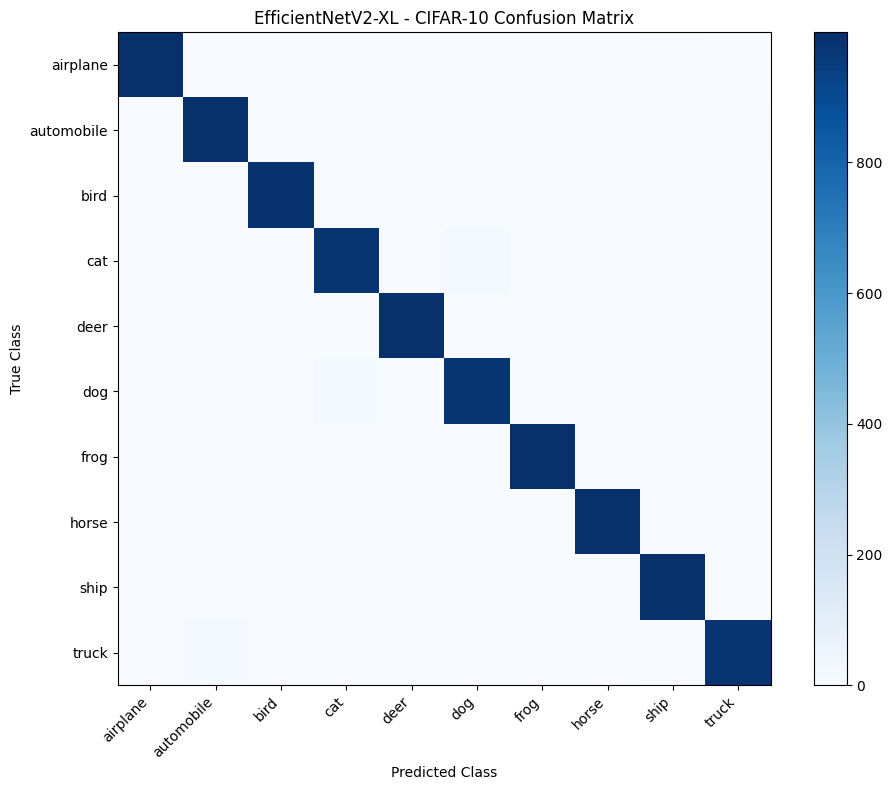

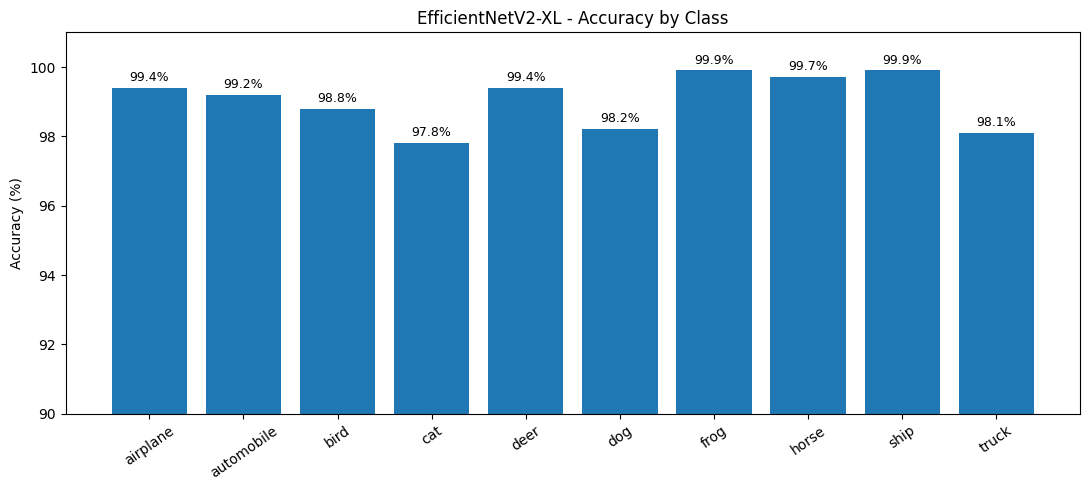


ALL EVALUATION FIGURES SAVED!
Folder: /content/drive/MyDrive/ARTI502_Assignment2/Report_Figures


In [9]:

# ==========================================
# ARTI 502 - Assignment 2
# Task 5: Detailed CNN Evaluation
# ==========================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import json
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# Output directory on Google Drive
REPORT_DIR = SAVE_DIR / "Report_Figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Use our previously loaded EfficientNetV2-XL
model.eval()

classes = test_data.classes

confusion = torch.zeros(
    (10, 10), dtype=torch.long
)

total_loss = 0.0
total_correct = 0
total_images = 0

# 1. Evaluate the CNN
with torch.inference_mode():

    for images, labels in tqdm(
        test_loader,
        desc="Detailed CNN Evaluation"
    ):

        images = images.to(device)

        with torch.autocast(
            "cuda",
            dtype=torch.float16
        ):
            logits = model(images)

        # Calculate test loss using FP32
        logits = logits.float()

        loss = F.cross_entropy(
            logits,
            labels.to(device),
            reduction="sum"
        )

        predictions = logits.argmax(
            dim=1
        ).cpu()

        total_loss += loss.item()
        total_correct += (
            predictions == labels
        ).sum().item()

        total_images += labels.size(0)

        # Build confusion matrix
        indices = labels * 10 + predictions

        confusion += torch.bincount(
            indices,
            minlength=100
        ).reshape(10, 10)

# 2. Final metrics
test_accuracy = (
    100 * total_correct / total_images
)

test_loss = total_loss / total_images

class_total = confusion.sum(dim=1)
class_correct = confusion.diag()

class_accuracy = (
    100 * class_correct.float()
    / class_total.clamp_min(1)
)

print("\n===== DETAILED TEST RESULTS =====")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Correct: {total_correct}/{total_images}")

print("\n===== PER-CLASS ACCURACY =====")
for name, acc in zip(classes, class_accuracy):
    print(f"{name:12s}: {acc.item():.2f}%")

# 3. Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    confusion.numpy(),
    cmap="Blues"
)

ax.set_xticks(range(10))
ax.set_yticks(range(10))

ax.set_xticklabels(
    classes,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title(
    "EfficientNetV2-XL - CIFAR-10 Confusion Matrix"
)

fig.colorbar(im, ax=ax)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "Task5_Confusion_Matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 4. Per-class accuracy chart
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    classes,
    class_accuracy.numpy()
)

ax.set_ylim(90, 101)
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "EfficientNetV2-XL - Accuracy by Class"
)

ax.tick_params(axis="x", rotation=35)

for bar, acc in zip(bars, class_accuracy):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{acc.item():.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "Task5_Per_Class_Accuracy.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 5. Save metrics
results = {
    "model": "EfficientNetV2-XL",
    "pretrained_source":
        "DeKUT-DSAIL/efficientnetv2-xl-cifar10-upsample",
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "correct": total_correct,
    "total": total_images,
    "per_class_accuracy": {
        name: float(acc)
        for name, acc in zip(classes, class_accuracy)
    },
    "confusion_matrix": confusion.tolist()
}

with open(
    REPORT_DIR / "Task5_Detailed_Results.json",
    "w"
) as f:
    json.dump(results, f, indent=2)

print("\nALL EVALUATION FIGURES SAVED!")
print("Folder:", REPORT_DIR)


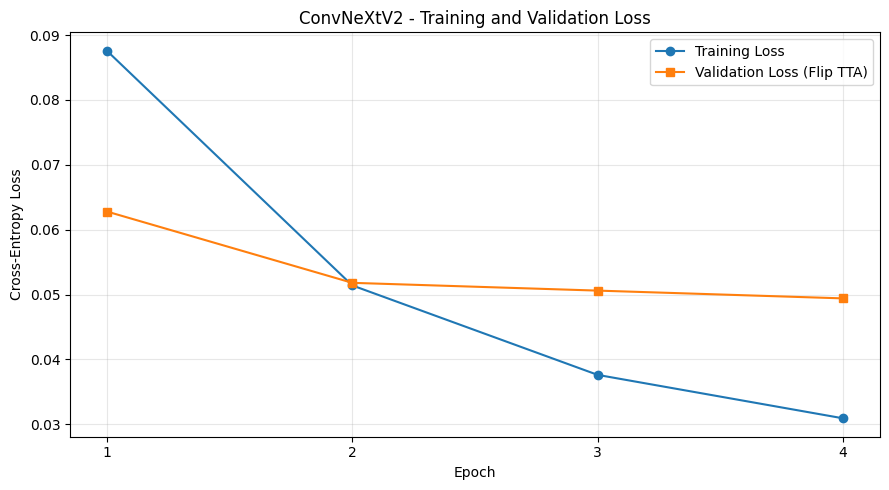

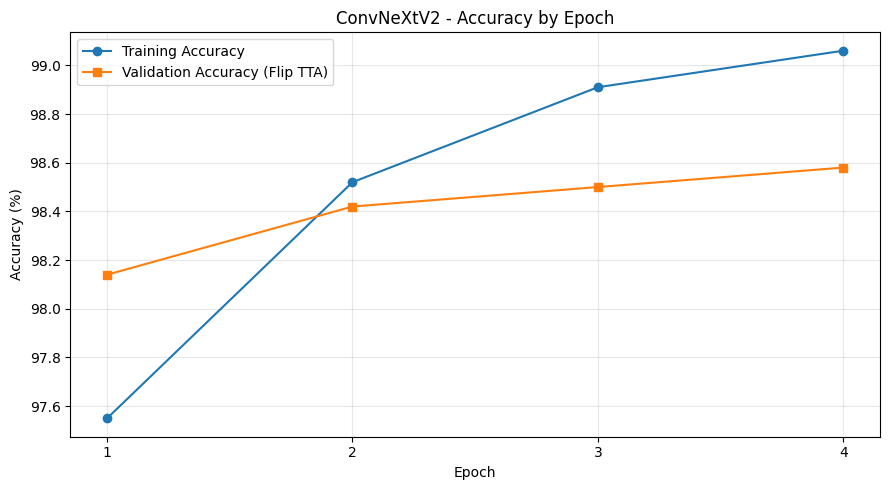

Training figures saved successfully!


In [10]:

import matplotlib.pyplot as plt
from pathlib import Path

report_dir = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2/Report_Figures"
)
report_dir.mkdir(parents=True, exist_ok=True)

# Actual ConvNeXtV2 fine-tuning logs
epochs = [1, 2, 3, 4]

train_loss = [0.0876, 0.0514, 0.0376, 0.0309]
val_loss = [0.0628, 0.0518, 0.0506, 0.0494]

train_acc = [97.55, 98.52, 98.91, 99.06]
val_acc = [98.14, 98.42, 98.50, 98.58]

# Figure 1: Loss curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, "o-", label="Training Loss")
plt.plot(epochs, val_loss, "s-", label="Validation Loss (Flip TTA)")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("ConvNeXtV2 - Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    report_dir / "Task5_Training_Validation_Loss.png",
    dpi=200
)
plt.show()

# Figure 2: Accuracy curves
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_acc, "o-", label="Training Accuracy")
plt.plot(epochs, val_acc, "s-", label="Validation Accuracy (Flip TTA)")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ConvNeXtV2 - Accuracy by Epoch")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    report_dir / "Task5_Training_Validation_Accuracy.png",
    dpi=200
)
plt.show()

print("Training figures saved successfully!")


In [11]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/ARTI502_Assignment2/"
    "Report_Figures/Task5_Detailed_Results.json"
)

with open(path) as f:
    results = json.load(f)

print("===== FINAL MODEL RESULTS =====")
print("Model:", results["model"])
print(f"Test Accuracy: {results['test_accuracy']:.2f}%")
print(f"Test Loss: {results['test_loss']:.6f}")
print(f"Correct Predictions: {results['correct']}/{results['total']}")


===== FINAL MODEL RESULTS =====
Model: EfficientNetV2-XL
Test Accuracy: 99.04%
Test Loss: 0.157579
Correct Predictions: 9904/10000
